# Домашнее задание 1. Свёртки, обучение глубоких сетей, adversarial robustness

**Дедлайн:** ДД.ММ.2026, 23:59 (3 недели).

- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры, cell metadata и открытые тесты сохраняйте; можно добавлять свои ячейки. Открытые тесты проверяют часть контракта, при оценке будут и другие входы в пределах условия.
- После вопроса приведите наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2–4 предложений; для составного вопроса можно ответить по пунктам. Отсутствие ожидаемого эффекта — допустимый результат, если эксперимент корректен и вы это обсудили.
- Разделы 1–4, 5.1 и 6 обязательны. В разделе 5 выберите **одну** задачу: 5.2 targeted или 5.3 transfer (`ATTACK_TRACK`). Обе дают по 2 балла; вторая ветка не добавляет баллы. Бонусы 7.1–7.5 выбираются отдельно через `BONUS_TASKS`; за бонусы суммарно можно получить до 4 баллов из 5 предложенных.
- `FAST_MODE = True` — проверка кода на небольшом бюджете; финальные эксперименты делаются с `False`. Не выбранная ветка и выключенные бонусы автоматически пропускаются, даже если их решения пустые.
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts`, который создаётся перед бонусами. Если сдаёте частичное решение, перечислите нерешённые задачи в ячейке ниже и приложите доступные результаты; ошибки и отсутствие зависимых результатов не скрывайте. Для частичной сдачи успешный Run All и полный каталог artifacts не требуются. Баллы выставляются по отдельным критериям, одна ошибка не обнуляет остальные задачи.
- Для CIFAR-10 рекомендуется CUDA GPU с 8 GB памяти или больше; подойдёт Colab T4. FashionMNIST тоже удобно считать на GPU: adversarial training и серии PGD могут занимать десятки минут и дольше на CPU. Реальное время зависит от устройства; замеряйте его в своих прогонах. Бонусы не входят в основной бюджет.
- Можно пользоваться документацией PyTorch и материалами курса. Нельзя вызывать готовую реализацию того, что просят написать (`torch.optim.AdamW` внутри `MyAdamW`, `nn.BatchNorm2d` внутри `MyBatchNorm2d` и т.п.). Повторно использовать код семинаров можно, указав источник.
- В обучающих моделях используйте библиотечные `nn.Conv2d` и `nn.BatchNorm2d`; собственные слои из разделов 1–2 проверяются отдельно. В `train_cifar` нужен ваш `MyAdamW`.

| раздел | задачи | баллы |
|---|---|---|
| 1. Свёртка изнутри | 1.1 `unfold` · 1.2 backward · 1.3 RF и effective RF | 3.5 |
| 2. Нормализация | 2.1 `BatchNorm2d` · 2.2 Conv–BN fusion | 2 |
| 3. Инициализация и optimizer | 3.1 масштаб активаций · 3.2 `AdamW` · 3.3 cosine schedule | 3 |
| 4. ResNet на CIFAR-10 | 4.1 архитектура · 4.2 обучение · 4.3 plain-20 vs plain-56 | 4.5 |
| 5. Атаки | 5.1 PGD-$L_2$ и **одна** из 5.2 / 5.3 | 3 |
| 6. Adversarial training | 6.1 PGD-AT · 6.2 диагностика · 6.3 input gradients | 4 |
| 7*. Бонусы | 7.1 edge of stability · 7.2 FFT · 7.3 Muon · 7.4 $L_0$ · 7.5 catastrophic overfitting | до +4 |
| итого | | 20 + 4 |

Внутри задачи отдельно оцениваются код, эксперимент и объяснение; разбивка указана у каждого задания. Для вычислительного эксперимента нужны корректный протокол и сохранённые результаты, для объяснения — опора на ваши числа и понимание ограничений. Конкретная accuracy и совпадение с «ожидаемой картинкой» сами по себе не являются критерием балла.

Примерный порядок на три недели: первая — разделы 1–3; вторая — CIFAR-10 и выбранная задача об атаках; третья — adversarial training, анализ результатов и финальный прогон.

**Сведения о сдаче.** Укажите устройство, выбранную ветку, использованные внешние источники и нерешённые задачи (если есть).

- **Устройство:** NVIDIA GeForce RTX 2060 (6 GB), CUDA; PyTorch 2.12.0+cu126, Python 3.13.12. Финальные эксперименты — с `FAST_MODE = False`.
- **Ветка раздела 5:** 5.3 transfer (`ATTACK_TRACK = 'transfer'`), 5.2 не выполнялась.
- **Бонусы:** 7.1, 7.2, 7.3, 7.4, 7.5.
- **Внешние источники:** документация PyTorch, статьи, на которые ссылается условие.
- **Нерешённые задачи:** нет.

In [278]:
# При необходимости, в отдельном окружении: %pip install -r requirements.txt
import copy
import itertools
import json
import math
from pathlib import Path
import time
import timeit

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import gradcheck
from torchvision import datasets

import typing as tp

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12

print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available:  {torch.cuda.is_available()}')
print(f'MPS available:   {torch.backends.mps.is_available()}')

PyTorch version: 2.12.0+cu126
CUDA available:  True
MPS available:   False


In [279]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    torch.manual_seed(seed)
    np.random.seed(seed)


device = get_device()
set_seed(0)
device

device(type='cuda')

In [280]:
FAST_MODE = False   # True — отладка, False — финальный прогон
DATA_ROOT = './data'
ATTACK_TRACK = 'transfer'   # 'targeted' (5.2) или 'transfer' (5.3)
BONUS_TASKS = set(['7.1', '7.2', '7.3', '7.4', '7.5'])        # например {'7.2', '7.4'}; пустое множество отключает все бонусы
assert ATTACK_TRACK in {'targeted', 'transfer'}
assert BONUS_TASKS <= {'7.1', '7.2', '7.3', '7.4', '7.5'}
RUN_TIMES = {}

Общие функции для разделов 4–7: данные лежат одним тензором на `device`, батчи режутся индексами (без `DataLoader` — так быстрее для маленьких картинок).

In [281]:
def iterate_batches(X, Y, batch_size, shuffle=True, transform=None):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for start in range(0, len(X), batch_size):
        b = idx[start:start + batch_size]
        yield (X[b] if transform is None else transform(X[b])), Y[b]


@torch.no_grad()
def predict_logits(model, X, batch_size=1000, transform=None):
    model.eval()
    return torch.cat([model(X[i:i + batch_size] if transform is None else transform(X[i:i + batch_size]))
                      for i in range(0, len(X), batch_size)])


def accuracy(logits, Y):
    return (logits.argmax(dim=1) == Y).float().mean().item()


def n_params(model):
    return sum(p.numel() for p in model.parameters())

---
# 1. Свёртка изнутри

## 1.1 `conv2d` через `unfold` (1 балл)

`F.unfold` (im2col) вырезает все патчи, которые видит ядро, и кладёт каждый патч столбцом:
$$
\mathrm{cols}[b,\, (c, u, v),\, \ell] = x_{\mathrm{pad}}\big[b,\, c,\; s\, i_\ell + d\, u,\; s\, j_\ell + d\, v\big], \qquad
\mathrm{cols} \in \mathbb R^{B \times C_{\text{in}} k_h k_w \times L}, \quad L = H_{\text{out}} W_{\text{out}},
$$
где $(i_\ell, j_\ell)$ — позиция $\ell$-го выхода. После этого свёртка — одно матричное умножение:
$$
y[b, o, \ell] = \sum_{(c, u, v)} W[o, (c, u, v)]\; \mathrm{cols}[b, (c, u, v), \ell] + \mathrm{bias}[o].
$$
С `groups = g` каналы делятся на $g$ групп: строки $\mathrm{cols}$ разбиваются на $g$ блоков по $\frac{C_{\text{in}}}{g} k_h k_w$, веса — на $g$ блоков по $\frac{C_{\text{out}}}{g}$ выходов, и каждая группа умножается только на свой блок.

Реализуйте `conv2d_unfold` для 4D-входа: stride, padding и dilation — целые числа или пары, groups — положительное целое, bias может быть `None`. Строковые padding и complex dtype не требуются. Циклов по батчу, каналам и позициям быть не должно.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [282]:
def pair(v):
    return v if isinstance(v, tuple) else (v, v)


def conv_output_size(size, kernel_size, stride=1, padding=0, dilation=1):
    return (size + 2 * padding - dilation * (kernel_size - 1) - 1) // stride + 1


def conv_output_shape(hw, kernel_size, stride: tuple | int = 1, padding: tuple | int = 0, dilation: tuple | int = 1):
    params = zip(hw, pair(kernel_size), pair(stride), pair(padding), pair(dilation))
    return tuple(conv_output_size(*p) for p in params)

In [283]:
def conv2d_unfold(x, weight, bias=None, stride=1, padding=0, dilation=1, groups=1):
    # x: (B, C_in, H, W), weight: (C_out, C_in / groups, kh, kw) -> (B, C_out, H_out, W_out)
    B, C_in, H, W = x.shape
    C_out, _, kh, kw = weight.shape

    stride_h, stride_w = pair(stride)
    pad_h, pad_w = pair(padding)
    dil_h, dil_w = pair(dilation)

    H_out, W_out = conv_output_shape((H, W), (kh, kw), (stride_h, stride_w), (pad_h, pad_w), (dil_h, dil_w))

    unfolded = F.unfold(x, (kh, kw), (dil_h, dil_w), (pad_h, pad_w), (stride_h, stride_w))

    unfolded_grouped = unfolded.view(B, groups, (C_in // groups) * kh * kw, -1)
    weight_grouped = weight.view(groups, C_out // groups, (C_in // groups) * kh * kw)

    res_grouped = torch.einsum('bgin,goi->bgon', unfolded_grouped, weight_grouped)
    res = res_grouped.contiguous().view(B, C_out, H_out, W_out)

    if bias is not None:
        res += bias.view(1, C_out, 1, 1)

    return res

In [284]:
torch.manual_seed(0)
x = torch.randn(2, 6, 11, 14)
n_checked = 0
for k, s, p, d, g in itertools.product([1, 3, (3, 5)], [1, 2, (2, 1)], [0, 1, (2, 1)], [1, 2], [1, 2, 3, 6]):
    if min(conv_output_shape((11, 14), k, s, p, d)) <= 0:
        continue
    w, b = torch.randn(12, 6 // g, *pair(k)), torch.randn(12)
    ref = F.conv2d(x, w, b, stride=s, padding=p, dilation=d, groups=g)
    assert torch.allclose(conv2d_unfold(x, w, b, s, p, d, g), ref, atol=1e-4), (k, s, p, d, g)
    assert torch.allclose(conv2d_unfold(x, w, None, s, p, d, g), ref - b[None, :, None, None], atol=1e-4)
    n_checked += 1
n_checked

216

**Вопрос.** Во сколько раз `cols` больше входа $x$ при $k = 3, 5, 7$ и `padding = k // 2`? Как стоимость im2col по памяти соотносится с тем, что FFT-свёртка выигрывает именно на больших ядрах?

In [285]:
x = torch.randn(8, 64, 32, 32)
for k in [3, 5, 7]:
    print(f'k = {k}: cols / x = {F.unfold(x, k, padding=k // 2).numel() / x.numel():.1f}')

k = 3: cols / x = 9.0
k = 5: cols / x = 25.0
k = 7: cols / x = 49.0


**Во сколько раз `cols` больше входа x?**

Ровно в $k^2$ раз: в $9$, $25$ и $49$ раз для $k = 3, 5, 7$. При $stride = 1$ и $padding = k // 2$ выход имеет тот же размер $H \times W$, значит положений ядра $L = H \cdot W$ и каждый столбец хранит патч из $C \cdot k^2$ чисел. Итого `cols` содержит $C \cdot k^2 \cdot H \cdot W$ элементов против $C \cdot H \cdot W$ у $x$

**Связь с FFT**

У im2col и память, и вычисления растут как $k^2$. Нужно материализовать cols размера $C \cdot k^2 \cdot H \cdot W$ и умножить на матрицу весов $O \times C \cdot k^2$. У FFT-свёртки стоимость от размера ядра почти не зависит. Ядро дополняется нулями до размера картинки, обе переводятся в частотную область за $O(H \cdot W \cdot \log(H \cdot W))$, и там свёртка становится поэлементным умножением. Память тоже порядка размера входа, без множителя $k^2$.

Поэтому на маленьких ядрах ($3 \times 3$) im2col выгоднее: множитель $9$ невелик, а у FFT есть накладные расходы (комплексные числа, паддинг ядра до размера картинки, прямое и обратное преобразование). С ростом $k$ множитель $k^2$ у im2col быстро раздувается ($49$ уже при $k = 7$), а стоимость FFT остаётся примерно той же.

## 1.2 Backward свёртки руками (1.5 балла)

Свёртка линейна по входу: $\mathrm{vec}(y) = M\, \mathrm{vec}(x) + b$ с разреженной матрицей $M$, в строках которой стоят веса ядра. Для $g = \partial L / \partial y$:
$$
\frac{\partial L}{\partial x} = M^\top g = \texttt{conv\_transpose2d}(g, W), \qquad
\frac{\partial L}{\partial W}[o, (c,u,v)] = \sum_{b,\ell} g[b, o, \ell]\; \mathrm{cols}[b, (c,u,v), \ell], \qquad
\frac{\partial L}{\partial b}[o] = \sum_{b, i, j} g[b, o, i, j].
$$
При stride $s > 1$ разные $H$ дают одинаковый $H_{\text{out}}$, и `conv_transpose2d` не знает, какой размер восстанавливать: нужную форму выбирает `output_padding`
$$
\mathrm{op}_H = H - \big((H_{\text{out}} - 1)s - 2p + k_h\big).
$$

Допишите `backward` (stride и padding — целые числа, dilation = 1, groups = 1). Проверка — `gradcheck` в float64 на размерах, где `output_padding` не равен нулю.

**Оценивание:** код — 1.2; эксперимент — 0; объяснение — 0.3 балла.

In [286]:
class Conv2dFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, weight, bias, stride, padding):
        ctx.save_for_backward(x, weight)
        ctx.stride, ctx.padding = stride, padding
        return F.conv2d(x, weight, bias, stride=stride, padding=padding)

    @staticmethod
    def backward(ctx, grad_out):
        x, weight = ctx.saved_tensors
        s, p = ctx.stride, ctx.padding
        N, C, H, W = x.shape
        O, _, kh, kw = weight.shape
        H_out, W_out = grad_out.shape[-2:]

        grad_x = grad_w = grad_b = None

        if ctx.needs_input_grad[0]:
            op_h = H - ((H_out - 1) * s - 2 * p + kh)
            op_w = W - ((W_out - 1) * s - 2 * p + kw)
            grad_x = F.conv_transpose2d(
                grad_out, weight, stride=s, padding=p, output_padding=(op_h, op_w)
            )

        if ctx.needs_input_grad[1]:
            cols = F.unfold(x, kernel_size=(kh, kw), padding=p, stride=s)
            g = grad_out.reshape(N, O, -1)
            grad_w = torch.einsum('bol,bkl->ok', g, cols).reshape(weight.shape)

        if ctx.needs_input_grad[2]:
            grad_b = grad_out.sum(dim=(0, 2, 3))

        return grad_x, grad_w, grad_b, None, None

In [287]:
torch.manual_seed(0)
n_checked = 0
for s, p, (H, W) in itertools.product([1, 2, 3], [0, 1, 2], [(7, 7), (8, 9), (10, 6)]):
    x = torch.randn(2, 3, H, W, dtype=torch.float64, requires_grad=True)
    w = torch.randn(4, 3, 3, 3, dtype=torch.float64, requires_grad=True)
    b = torch.randn(4, dtype=torch.float64, requires_grad=True)
    assert gradcheck(lambda x, w, b: Conv2dFunction.apply(x, w, b, s, p), (x, w, b)), (s, p, H, W)
    n_checked += 1
n_checked

27

**Вопрос.** Приведите два размера $H$, для которых свёртка $3 \times 3$ со stride 2 и padding 1 даёт одинаковый $H_{\text{out}}$, и `output_padding` для каждого.

Например, $H = 7$ и $H = 8$, оба дают $H_{out} = 4$:

Посчитаем по формуле размер выхода
- $H = 7: \lfloor 6 / 2 \rfloor + 1 = 3 + 1 = 4$
- $H = 8: \lfloor 7 / 2 \rfloor + 1 = 3 + 1 = 4$

Теперь `output_padding`. Транспонированная свертка по $H_{out} = 4$ по умолчанию восстанавливает размер $(H_{out} - 1) \cdot s - 2p + k = 3 \cdot 2 - 2 + 3 = 7$ 
- $H = 7: op = 7 - 7 = 0$
- $H = 8: op = 8 - 7 = 1$

## 1.3 Receptive field через autograd (1 балл)

Теоретический receptive field (RF) нейрона — область входа, потенциально влияющая на него по архитектуре. Носитель градиента на конкретном входе может быть меньше из-за ReLU, MaxPool или взаимных сокращений. Размер bounding box теоретического RF вдали от границ даёт рекурсия (функция `receptive_field` ниже) по слоям с ядром $k_l$, stride $s_l$ и dilation $d_l$:
$$
k_l^{\mathrm{eff}} = 1 + d_l (k_l - 1), \qquad r_0 = j_0 = 1, \qquad r_l = r_{l-1} + (k_l^{\mathrm{eff}} - 1)\, j_{l-1}, \qquad j_l = j_{l-1}\, s_l,
$$
$j_l$ — расстояние между соседними нейронами слоя $l$ в пикселях входа. Pooling считается так же.

Сети для проверки — свёртки с усредняющими ядрами (все веса $1/k^2$, bias 0) и `AvgPool`, без нелинейностей.

Реализуйте `empirical_rf`: по градиенту суммы каналов центрального выхода по входу найти размер bounding box ненулевых пикселей по высоте и ширине.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [288]:
def receptive_field(layers):
    # layers: список dict(k, s=1, d=1); возвращает (r, j) после каждого слоя
    r, j = 1, 1
    history = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        r = r + (1 + d * (k - 1) - 1) * j
        j = j * s
        history.append((r, j))
    return history


def make_avg_net(layers, max_pool=False):
    modules = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        if layer.get('pool'):
            modules.append(nn.MaxPool2d(k, s) if max_pool else nn.AvgPool2d(k, s))
        else:
            conv = nn.Conv2d(1, 1, k, stride=s, dilation=d)
            nn.init.constant_(conv.weight, 1 / k ** 2)
            nn.init.zeros_(conv.bias)
            modules.append(conv)
    return nn.Sequential(*modules)


RF_ARCHS = {
    'conv3x3 x4': [dict(k=3)] * 4,
    'conv-pool':  [dict(k=3), dict(k=2, s=2, pool=True), dict(k=3), dict(k=2, s=2, pool=True), dict(k=3)],
    'strided':    [dict(k=5, s=2), dict(k=3, s=2), dict(k=3)],
    'dilated':    [dict(k=3, d=1), dict(k=3, d=2), dict(k=3, d=4)],
}

In [289]:
def center_input_grad(model, x):
    x = x.detach().requires_grad_(True)
    y = model(x)
    h_out, w_out = y.shape[-2:]
    center = y[:, :, h_out // 2, w_out // 2].sum()
    return torch.autograd.grad(center, x)[0]


def empirical_rf(model, in_channels=1, size=96):
    # -> (высота, ширина) bounding box пикселей входа, влияющих на центральный выход
    x = torch.randn(1, in_channels, size, size, requires_grad=True)
    support = center_input_grad(model, x).abs().sum(dim=(0, 1)) > 0
    rows = support.any(dim=1).nonzero()
    cols = support.any(dim=0).nonzero()
    return (rows.max() - rows.min() + 1).item(), (cols.max() - cols.min() + 1).item()

In [290]:
torch.manual_seed(0)
for name, layers in RF_ARCHS.items():
    r = receptive_field(layers)[-1][0]
    assert empirical_rf(make_avg_net(layers)) == (r, r), name
    print(f'{name:<12} r = {r:>3}   MaxPool instead of AvgPool: {empirical_rf(make_avg_net(layers, max_pool=True))}')

conv3x3 x4   r =   9   MaxPool instead of AvgPool: (9, 9)
conv-pool    r =  18   MaxPool instead of AvgPool: (18, 18)
strided      r =  17   MaxPool instead of AvgPool: (17, 17)
dilated      r =  15   MaxPool instead of AvgPool: (15, 15)


In [291]:
torch.manual_seed(0)
for is_max_pool in [False, True]:
    net = make_avg_net(RF_ARCHS['conv-pool'], max_pool=is_max_pool)
    boxes = sorted({empirical_rf(net) for _ in range(20)})
    n_nonzero = (center_input_grad(net, torch.randn(1, 1, 96, 96)) != 0).sum().item()
    print(f'MaxPool={is_max_pool!s:<5}  nonzero pixels: {n_nonzero:>3}   bounding boxes: {boxes}')

MaxPool=False  nonzero pixels: 324   bounding boxes: [(18, 18)]
MaxPool=True   nonzero pixels: 237   bounding boxes: [(14, 14), (15, 18), (16, 15), (16, 17), (16, 18), (17, 18), (18, 14), (18, 16), (18, 17), (18, 18)]


**Вопрос.** Почему для проверки взяты усредняющие ядра без нелинейностей? Что меняется с `MaxPool` и почему?

**Ответ.** В усредняющей сети без нелинейностей все веса положительные, поэтому градиент центрального выхода — это просто многократная свёртка положительных ядер. Сокращаться там нечему, и градиент ненулевой ровно на всём теоретическом RF при любом входе. Значит, bounding box ненулевого градиента обязан совпасть с формулой, и тест получается честным: у ReLU градиент мог бы обнулиться, а случайные веса разных знаков могли бы где-то случайно взаимно сократиться.

С `MaxPool` градиент проходит только через argmax каждого окна, остальные пиксели окна получают ноль. Носитель градиента становится дырявым и зависит от входа. В `conv-pool` (ячейка выше) на случайном входе ненулевых пикселей 237 против 324 у AvgPool, а bounding box на 20 разных входах гуляет от 14×14 до 18×18. В таблице выше вышло 18×18 просто потому, что при этом seed крайние пиксели попали в argmax. У остальных трёх архитектур pooling нет, поэтому для них ничего не меняется.

### Effective receptive field

Для рассматриваемых усредняющих сетей носитель градиента совпадает с теоретическим RF, но вклад пикселей неравномерный. Для стопки из $L$ усредняющих свёрток $3 \times 3$ карта $\partial y_{\text{center}} / \partial x$ — это $L$-кратная свёртка равномерного ядра, то есть распределение суммы $L$ независимых равномерных величин на $\{-1, 0, 1\}$ по каждой оси:
$$
\sigma_{\text{ERF}} = \sqrt{L \cdot \tfrac23}, \qquad r_L = 2L + 1.
$$
По ЦПТ профиль близок к гауссовскому, и эффективная ширина растёт как $\sqrt L$: [Understanding the Effective Receptive Field in Deep Convolutional Neural Networks](https://arxiv.org/pdf/1701.04128), Luo et al., 2016.

Реализуйте `erf_std`: $|\nabla_x y_{\text{center}}|$, усреднённый по `n_inputs` случайным входам и просуммированный по каналам, нормировать в распределение по строкам и вернуть его стандартное отклонение (в пикселях).

In [292]:
def erf_std(model, in_channels=1, size=96, n_inputs=1):
    x = torch.randn(n_inputs, in_channels, size, size)
    grad_map = center_input_grad(model, x).abs().mean(dim=0).sum(dim=0)
    row_weights = grad_map.sum(dim=1)
    p = row_weights / row_weights.sum()
    positions = torch.arange(size, dtype=p.dtype)
    mean = (p * positions).sum()
    return ((p * (positions - mean) ** 2).sum().sqrt()).item()

In [293]:
for L in [1, 2, 4, 8, 16]:
    assert abs(erf_std(make_avg_net([dict(k=3)] * L)) - math.sqrt(2 * L / 3)) < 1e-3, L

Теперь обычная сеть: $L$ свёрток $3 \times 3$ по 16 каналов, ReLU, веса из $\mathcal N(0,\, 2 / \text{fan\_in})$, среднее по 16 входам.

In [294]:
def make_relu_net(L, width=16, seed=0):
    torch.manual_seed(seed)
    layers, c = [], 1
    for _ in range(L):
        conv = nn.Conv2d(c, width, 3)
        nn.init.kaiming_normal_(conv.weight, nonlinearity='relu')
        nn.init.zeros_(conv.bias)
        layers += [conv, nn.ReLU()]
        c = width
    return nn.Sequential(*layers)


depths = [1, 2, 4, 8, 16]
erf = {'theoretical RF / 2': [float(L) for L in depths],
       'ERF std, averaging kernels': [erf_std(make_avg_net([dict(k=3)] * L)) for L in depths],
       'ERF std, random ReLU net': [erf_std(make_relu_net(L), n_inputs=16) for L in depths]}
for name, values in erf.items():
    print(f'{name:<28}' + ''.join(f'{v:>7.2f}' for v in values))

theoretical RF / 2             1.00   2.00   4.00   8.00  16.00
ERF std, averaging kernels     0.82   1.15   1.63   2.31   3.27
ERF std, random ReLU net       0.79   1.29   1.97   3.08   4.44


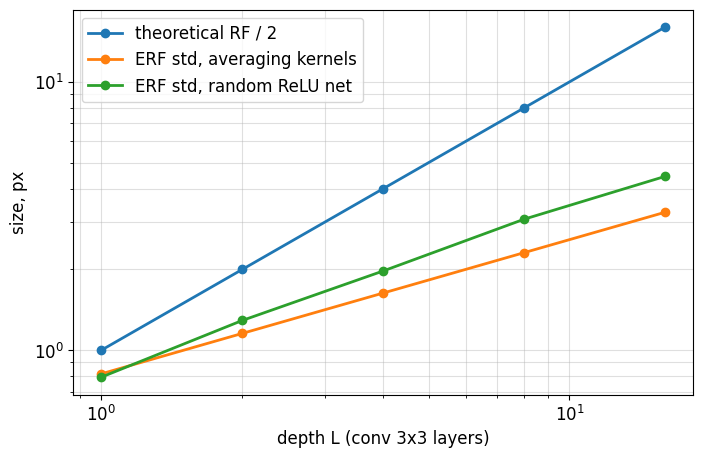

In [295]:
plt.figure(figsize=(8, 5))
for name, values in erf.items():
    plt.loglog(depths, values, 'o-', linewidth=2, label=name)
plt.xlabel('depth L (conv 3x3 layers)')
plt.ylabel('size, px')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Как отношение эффективного RF к теоретическому меняется с глубиной (наклоны на log-log графике)? Как ведёт себя сеть с ReLU по сравнению с усредняющей?

**Ответ.** Теоретический RF растёт линейно (наклон 1), а ERF у усредняющей сети — как $\sqrt L$: от 0.82 до 3.27 при росте глубины в 16 раз, наклон ровно 0.5. Получается, отношение ERF/RF падает как $1/\sqrt L$: при $L = 1$ это 0.82, при $L = 16$ уже 0.20. Глубокий нейрон формально видит большую область, но реально почти весь вклад идёт от небольшого пятна в центре.

ReLU-сеть со случайными весами ведёт себя похоже, но ERF у неё чуть шире и растёт немного быстрее: от 0.79 до 4.44, наклон около 0.6, отношение к RF при $L = 16$ около 0.28. Видимо, у случайного ядра вес не сосредоточен в центре, как у равномерного, плюс берём модуль градиента, поэтому каждый слой размазывает сильнее. Но рост всё равно заметно медленнее линейного. Это одна случайная инициализация и всего 16 входов, так что разница наклонов 0.5 и 0.6 — оценка грубая.

---
# 2. Нормализация

## 2.1 `BatchNorm2d` с нуля (1 балл)

В `train()`: статистики текущего батча по каналу (среднее по $b, h, w$), нормировка смещённой дисперсией и обновление буферов
$$
\hat\mu \leftarrow (1 - m)\,\hat\mu + m\, \mu_{\text{batch}}, \qquad
\hat\sigma^2 \leftarrow (1 - m)\,\hat\sigma^2 + m\, \frac{n}{n - 1}\, \sigma^2_{\text{batch}}, \qquad n = BHW,
$$
в running-дисперсию идёт несмещённая оценка. В `eval()` — нормировка по $\hat\mu, \hat\sigma^2$. Параметры `weight` ($\gamma$) и `bias` ($\beta$), буферы `running_mean`, `running_var`, `num_batches_tracked` — с теми же именами, что в `nn.BatchNorm2d`, чтобы `load_state_dict` был совместим.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [296]:
class MyBatchNorm2d(nn.Module):
    def __init__(self, num_features, eps=1e-5, momentum=0.1):
        super().__init__()
        self.eps, self.momentum = eps, momentum

        self.weight = nn.Parameter(torch.ones(num_features))
        self.bias = nn.Parameter(torch.zeros(num_features))

        self.register_buffer('running_mean', torch.zeros(num_features))
        self.register_buffer('running_var', torch.ones(num_features))
        self.register_buffer('num_batches_tracked', torch.tensor(0, dtype=torch.long))

    def forward(self, x):
        if self.training:
            n = x.numel() // x.shape[1]
            var, mu = torch.var_mean(x, dim=(0, 2, 3), correction=0)

            with torch.no_grad():
                self.running_mean.mul_(1 - self.momentum).add_(self.momentum * mu)
                self.running_var.mul_(1 - self.momentum).add_(self.momentum * n / (n - 1) * var)
                self.num_batches_tracked.add_(1)

            x = (x - mu.view(1, -1, 1, 1)) / torch.sqrt(var.view(1, -1, 1, 1) + self.eps)
            x = x * self.weight.view(1, -1, 1, 1) + self.bias.view(1, -1, 1, 1)

        else:
            x = (x - self.running_mean.view(1, -1, 1, 1)) / torch.sqrt(self.running_var.view(1, -1, 1, 1) + self.eps)
            x = x * self.weight.view(1, -1, 1, 1) + self.bias.view(1, -1, 1, 1)

        return x

In [297]:
torch.manual_seed(0)
mine, ref = MyBatchNorm2d(8), nn.BatchNorm2d(8)
assert set(dict(mine.named_parameters())) == {'weight', 'bias'}
assert set(dict(mine.named_buffers())) == {'running_mean', 'running_var', 'num_batches_tracked'}
with torch.no_grad():
    for m in (mine, ref):
        m.weight.copy_(torch.linspace(0.5, 2, 8))
        m.bias.copy_(torch.linspace(-1, 1, 8))

for step in range(10):
    x = (torch.randn(4, 8, 5, 5) * 3 + 2).requires_grad_(True)
    out_mine, out_ref = mine(x), ref(x)
    assert torch.allclose(out_mine, out_ref, atol=1e-5), step
    g = torch.randn_like(out_ref)
    grads_mine = torch.autograd.grad(out_mine, (x, mine.weight, mine.bias), g)
    grads_ref = torch.autograd.grad(out_ref, (x, ref.weight, ref.bias), g)
    assert all(torch.allclose(a, b, atol=1e-4) for a, b in zip(grads_mine, grads_ref)), step

for name, buf in ref.named_buffers():
    assert torch.allclose(getattr(mine, name).float(), buf.float(), atol=1e-5), name

mine.eval(), ref.eval()
x = torch.randn(4, 8, 5, 5)
assert torch.allclose(mine(x), ref(x), atol=1e-5)
mine.load_state_dict(ref.state_dict())

<All keys matched successfully>

**Вопрос.** Почему в running-дисперсию идёт несмещённая оценка, а в нормировку батча — смещённая? Насколько они различаются при $B = 4$ и карте $5 \times 5$, и при $B = 2$ и карте $1 \times 1$?

**Ответ.** В нормировку батча идёт смещённая дисперсия, потому что там мы не оцениваем ничего про генеральную совокупность. Мы нормируем ровно эти $n$ чисел, и нужно, чтобы у них самих было среднее 0 и дисперсия 1. Это и есть их эмпирическая дисперсия с делением на $n$. С поправкой $n/(n-1)$ нормированный батч имел бы дисперсию меньше единицы. Running-статистики нужны для другого: в `eval()` они подставляются вместо статистик батча, то есть должны оценивать дисперсию активаций по всем данным. А смещённая оценка, посчитанная с выборочным средним, в среднем занижает настоящую дисперсию в $(n-1)/n$ раз. Поэтому в буфер идёт несмещённая.

Разница — множитель $n/(n-1)$, где $n = BHW$:
- $B = 4$, карта $5 \times 5$: $n = 100$, множитель $100/99 \approx 1.010$. Разница около 1%, на практике почти незаметна.
- $B = 2$, карта $1 \times 1$: $n = 2$, множитель 2. Несмещённая оценка ровно вдвое больше смещённой.

Во втором случае плохо не только с дисперсией. Для двух чисел $a, b$ смещённая дисперсия равна $((a-b)/2)^2$, и после нормировки выход всегда $\pm 1$ (с точностью до $\epsilon$), что бы ни было на входе. Информации о величине активаций не остаётся, а running-статистики по таким батчам очень шумные. Поэтому BN с крошечными батчами и картами $1 \times 1$ работает плохо.

## 2.2 Слияние свёртки и BatchNorm для инференса (1 балл)

В `eval()` BN — поканальное аффинное преобразование с фиксированными $\hat\mu, \hat\sigma^2$, поэтому $\mathrm{BN}(\mathrm{conv}(x))$ — снова свёртка с другими весами $W'$ и bias $b'$.

1. Выведите $W'$ и $b'$ в ячейке «Ответ» ниже.
2. Реализуйте `fuse_conv_bn(conv, bn)`, возвращающую новую `nn.Conv2d`: сохраняются `dtype`, `device`, `padding_mode`, `groups`, stride, padding и dilation; bias у исходной свёртки может отсутствовать. Входные модули в `eval()`, BN с affine и running statistics; исходные веса не менять.
3. Реализуйте `fuse_sequential(seq)` для плоского `nn.Sequential` в `eval()`: каждую соседнюю пару `Conv2d, BatchNorm2d` заменить свёрткой. Остальные модули скопировать через `copy.deepcopy`, исходную сеть не менять; рекурсивный обход вложенных контейнеров не требуется.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

**Ответ.** В `eval()` BN для канала $o$ — это $y_o = \gamma_o \dfrac{z_o - \hat\mu_o}{\sqrt{\hat\sigma^2_o + \epsilon}} + \beta_o$, где $z_o = (W_o * x) + b_o$ — выход свёртки. Обозначим масштаб $s_o = \dfrac{\gamma_o}{\sqrt{\hat\sigma^2_o + \epsilon}}$. Тогда
$$
y_o = s_o (W_o * x) + s_o (b_o - \hat\mu_o) + \beta_o,
$$
и так как свёртка линейна по весам, $s_o (W_o * x) = (s_o W_o) * x$. Получаем
$$
W'[o, :, :, :] = s_o\, W[o, :, :, :], \qquad b'_o = s_o\,(b_o - \hat\mu_o) + \beta_o.
$$
Если у свёртки нет bias, берём $b_o = 0$. Каждый выходной канал масштабируется независимо, поэтому для `groups`, stride, padding и dilation ничего не меняется: они на этот множитель не влияют, их просто копируем.

In [298]:
@torch.no_grad()
def fuse_conv_bn(conv, bn):
    scale = bn.weight / torch.sqrt(bn.running_var + bn.eps)
    conv_bias = conv.bias if conv.bias is not None else torch.zeros_like(bn.running_mean)

    fused = nn.Conv2d(conv.in_channels, conv.out_channels, conv.kernel_size,
                      stride=conv.stride, padding=conv.padding, dilation=conv.dilation,
                      groups=conv.groups, bias=True, padding_mode=conv.padding_mode,
                      device=conv.weight.device, dtype=conv.weight.dtype)
    fused.weight.copy_(conv.weight * scale.view(-1, 1, 1, 1))
    fused.bias.copy_((conv_bias - bn.running_mean) * scale + bn.bias)
    return fused.train(conv.training)


def fuse_sequential(seq):
    modules = list(seq)
    fused_modules = []
    i = 0
    while i < len(modules):
        is_conv_bn_pair = (i + 1 < len(modules) and isinstance(modules[i], nn.Conv2d)
                           and isinstance(modules[i + 1], nn.BatchNorm2d))
        if is_conv_bn_pair:
            fused_modules.append(fuse_conv_bn(modules[i], modules[i + 1]))
            i += 2
        else:
            fused_modules.append(copy.deepcopy(modules[i]))
            i += 1
    return nn.Sequential(*fused_modules)

In [299]:
torch.manual_seed(0)
for cfg in [dict(bias=True), dict(bias=False), dict(groups=4), dict(stride=2, padding=1, dilation=2)]:
    conv, bn = nn.Conv2d(8, 16, 3, **cfg), nn.BatchNorm2d(16)
    with torch.no_grad():
        bn.weight.uniform_(0.5, 2)
        bn.bias.uniform_(-1, 1)
        for _ in range(5):
            bn(conv(torch.randn(8, 8, 12, 12) * 2 + 1))   # накопить running-статистики
    conv.eval(), bn.eval()
    x = torch.randn(4, 8, 12, 12)
    fused = fuse_conv_bn(conv, bn)
    assert isinstance(fused, nn.Conv2d)
    assert torch.allclose(fused(x), bn(conv(x)), atol=1e-5), cfg

conv = nn.Conv2d(4, 8, 3, padding=1, padding_mode='reflect', groups=2, bias=False).double().eval()
bn = nn.BatchNorm2d(8).double().eval()
x = torch.randn(2, 4, 9, 11, dtype=torch.float64)
fused = fuse_conv_bn(conv, bn)
assert fused.weight.dtype == x.dtype and fused.padding_mode == 'reflect'
assert torch.allclose(fused(x), bn(conv(x)), atol=1e-10, rtol=1e-10)

In [300]:
def make_vgg_like(width=64, n_blocks=6):
    layers, c = [], 3
    for i in range(n_blocks):
        layers += [nn.Conv2d(c, width, 3, padding=1, bias=False), nn.BatchNorm2d(width), nn.ReLU()]
        c = width
        if i % 2 == 1:
            layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(width, 10))


torch.manual_seed(0)
vgg = make_vgg_like()
with torch.no_grad():
    for _ in range(5):
        vgg(torch.randn(32, 3, 32, 32))   # train-режим: копим статистики
vgg.eval()
vgg_fused = fuse_sequential(vgg).eval()
x = torch.randn(64, 3, 32, 32)
assert not any(isinstance(m, nn.BatchNorm2d) for m in vgg_fused.modules())
assert torch.allclose(vgg(x), vgg_fused(x), atol=1e-4)

In [301]:
with torch.inference_mode():
    t_bn = min(timeit.repeat(lambda: vgg(x), number=5, repeat=5)) / 5
    t_fused = min(timeit.repeat(lambda: vgg_fused(x), number=5, repeat=5)) / 5
print(f'Conv + BN: {t_bn * 1000:.1f} ms   fused: {t_fused * 1000:.1f} ms   speedup {t_bn / t_fused:.2f}x')

Conv + BN: 25.5 ms   fused: 24.1 ms   speedup 1.06x


In [302]:
def time_forward(model, x, number=20, repeat=5):
    def run():
        model(x)
        if x.is_cuda:
            torch.cuda.synchronize()
    run()
    return min(timeit.repeat(run, number=number, repeat=repeat)) / number


with torch.inference_mode():
    for dev in [torch.device('cpu'), device]:
        vgg_dev, fused_dev = copy.deepcopy(vgg).to(dev), copy.deepcopy(vgg_fused).to(dev)
        for batch_size in [1, 64]:
            x_dev = torch.randn(batch_size, 3, 32, 32, device=dev)
            t_bn, t_fused = time_forward(vgg_dev, x_dev), time_forward(fused_dev, x_dev)
            print(f'{dev.type:<5} B={batch_size:<3} Conv + BN: {t_bn * 1000:6.2f} ms   fused: {t_fused * 1000:6.2f} ms   speedup {t_bn / t_fused:.2f}x')

cpu   B=1   Conv + BN:   0.81 ms   fused:   0.56 ms   speedup 1.46x
cpu   B=64  Conv + BN:  26.31 ms   fused:  25.37 ms   speedup 1.04x
cuda  B=1   Conv + BN:   0.56 ms   fused:   0.50 ms   speedup 1.12x
cuda  B=64  Conv + BN:   2.18 ms   fused:   2.17 ms   speedup 1.01x


**Вопрос.** Почему слияние корректно только в `eval()`? Что даёт слияние и от чего зависит выигрыш?

**Ответ.** В `train()` BN нормирует по статистикам текущего батча. Это уже не константы: $\mu$ и $\sigma^2$ зависят от того, какие картинки попали в батч, и градиент течёт в том числе через них. Зашить такое в фиксированные $W'$ и $b'$ нельзя. В `eval()` $\hat\mu, \hat\sigma^2$ заморожены, BN становится обычным поканальным аффинным преобразованием, и его можно влить в свёртку.

Сама свёртка после слияния стоит столько же, а BN исчезает целиком: одним проходом чтения-записи по карте активаций и одним запуском ядра меньше. Поэтому выигрыш зависит от того, какую долю времени занимал BN. На GPU с батчем 1, где время в основном уходит на запуски ядер, слияние дало 1.54x. С батчем 64 почти всё время съедают сами свёртки, и выходит 1.01x. На CPU эффект тонет в шуме: от 0.87x до 1.08x, а между перезапусками те же замеры прыгали в пределах примерно 0.9–1.15x. Так что для больших батчей это скорее упрощение графа, чем ускорение, а заметная польза — в инференсе маленькими батчами на GPU.

---
# 3. Инициализация и оптимизатор

## 3.1 Дисперсия активаций по глубине (1 балл)

Слой $h = W z$, $W_{ij}$ независимы, $\mathbb E W_{ij} = 0$, $\mathrm{Var}\, W_{ij} = v$, $W$ не зависит от $z \in \mathbb R^{n}$:
$$
\mathrm{Var}(h_i) = n\, v\; \mathbb E\big[z_j^2\big].
$$

1. В ячейке «Ответ» ниже выведите $v$, при котором $\mathrm{Var}(h)$ не меняется от слоя к слою, для $z = \mathrm{ReLU}(h^{\text{prev}})$ с симметричным $h^{\text{prev}}$ и для $\tanh$ в линейном режиме. Инициализация `nn.Linear` по умолчанию — $\mathcal U(-1/\sqrt n,\, 1/\sqrt n)$: во сколько раз за слой меняется стандартное отклонение активаций для ReLU?
2. Реализуйте `activation_stds`: MLP глубины 50 и ширины 256 без bias, на входе $\mathcal N(0, I)$, вернуть `h.std().item()` после каждой активации — по **всем** элементам тензора `(n, width)`, а не среднее std по отдельным нейронам. Верните список из `depth` чисел.

**Оценивание:** код — 0.3; эксперимент — 0.3; объяснение — 0.4 балла.

**Ответ.**

**ReLU.** Если $h^{\text{prev}}$ симметрична относительно нуля, то ReLU оставляет ровно половину её «массы»: $\mathbb E[z_j^2] = \mathbb E[h_j^2 \cdot \mathbb 1\{h_j > 0\}] = \tfrac12 \mathrm{Var}(h^{\text{prev}})$. Подставляем в формулу: $\mathrm{Var}(h) = n v \cdot \tfrac12 \mathrm{Var}(h^{\text{prev}})$. Чтобы дисперсия не менялась, нужно $v = \dfrac{2}{n}$ — это инициализация Kaiming (He).

**tanh в линейном режиме.** Около нуля $\tanh(h) \approx h$, поэтому $\mathbb E[z_j^2] \approx \mathrm{Var}(h^{\text{prev}})$ и нужно $v = \dfrac{1}{n}$. Xavier даёт $v = \dfrac{2}{n_{\text{in}} + n_{\text{out}}}$, для квадратных слоёв это ровно $1/n$.

**Инициализация `nn.Linear` по умолчанию.** У $\mathcal U(-a, a)$ дисперсия $a^2 / 3$, значит $v = \dfrac{1}{3n}$. Для ReLU получаем $\mathrm{Var}(h) = n \cdot \dfrac{1}{3n} \cdot \tfrac12 \mathrm{Var}(h^{\text{prev}}) = \tfrac16 \mathrm{Var}(h^{\text{prev}})$. Стандартное отклонение за каждый слой умножается на $1/\sqrt6 \approx 0.41$, то есть падает примерно в 2.45 раза. Эксперимент ниже даёт средний множитель 0.409.

In [303]:
INITS = {
    'N(0, 0.01^2)':    lambda w: nn.init.normal_(w, std=0.01),
    'PyTorch default': lambda w: nn.init.kaiming_uniform_(w, a=math.sqrt(5)),
    'Xavier':          nn.init.xavier_normal_,
    'Kaiming':         lambda w: nn.init.kaiming_normal_(w, nonlinearity='relu'),
}


@torch.no_grad()
def activation_stds(init, act, depth=50, width=256, n=1024, seed=0):
    torch.manual_seed(seed)
    h = torch.randn(n, width)
    stds = []
    for _ in range(depth):
        weight = torch.empty(width, width)
        init(weight)
        h = act(h @ weight.T)
        stds.append(h.std().item())
    return stds

In [304]:
stds = {(name, act_name): activation_stds(init, act)
        for name, init in INITS.items() for act_name, act in [('tanh', torch.tanh), ('ReLU', torch.relu)]}

kaiming_relu = stds['Kaiming', 'ReLU']
assert len(kaiming_relu) == 50 and np.isfinite(kaiming_relu).all()
print(f'Kaiming + ReLU, last / first std: {kaiming_relu[-1] / kaiming_relu[0]:.3f}')
default_relu = np.array(stds['PyTorch default', 'ReLU'])
rate = np.exp(np.mean(np.diff(np.log(default_relu))))   # средний множитель std за слой
assert abs(rate - 1 / math.sqrt(6)) < 1e-3
rate

Kaiming + ReLU, last / first std: 0.758


np.float64(0.40910241812972786)

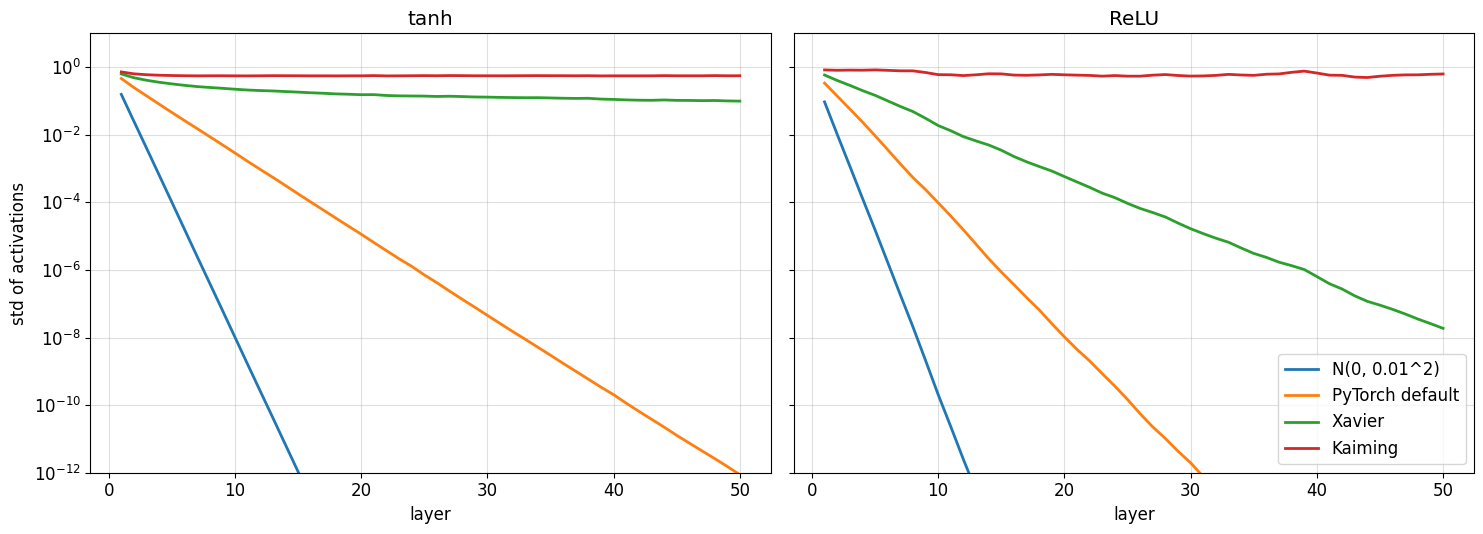

In [305]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, act_name in zip(axes, ['tanh', 'ReLU']):
    for name in INITS:
        ax.semilogy(range(1, 51), stds[name, act_name], linewidth=2, label=name)
    ax.set_title(act_name)
    ax.set_xlabel('layer')
    ax.grid(True, which='both', alpha=0.4)
axes[0].set_ylabel('std of activations')
axes[0].set_ylim(1e-12, 10)
axes[1].legend()
plt.tight_layout()
plt.show()

**Вопрос.** Какие пары (инициализация, активация) сохраняют масштаб на 50 слоях? Почему сети с инициализацией PyTorch по умолчанию всё равно обучаются (например, ResNet в задаче 4.2)?

**Ответ.** Масштаб держат две пары. **Kaiming + ReLU:** std на первом слое 0.83, на последнем 0.63. Систематического затухания нет, это просто случайное блуждание из-за конечной ширины 256. **Kaiming + tanh:** std быстро выходит на уровень около 0.56 и дальше стоит. Дисперсия весов $2/n$ для tanh великовата, но tanh насыщается и сжимает большие значения, так что устанавливается равновесие. **Xavier + tanh** почти держит: за 50 слоёв std падает с 0.63 до 0.10, примерно в 6 раз, но медленно, а не экспоненциально. Вне линейного режима tanh чуть сжимает сигнал на каждом слое. Остальные пары затухают экспоненциально. Xavier + ReLU теряет $\sqrt2$ за слой и к концу даёт $2 \cdot 10^{-8}$. Дефолтная инициализация с ReLU доходит до $3 \cdot 10^{-20}$, а $\mathcal N(0, 0.01^2)$ с ReLU вообще уходит в ноль: числа меньше минимального float32.

Почему ResNet с дефолтной инициализацией всё равно учится. В нём после каждой свёртки стоит BatchNorm, и он заново приводит активации к единичной дисперсии, как бы ни были отмасштабированы веса. Поэтому множитель 0.41 не накапливается от слоя к слою. Плюс residual-связи: сигнал идёт по identity-пути в обход свёрток и не затухает с глубиной, и градиент назад тоже. В голом MLP без нормализации ни того ни другого нет, поэтому там дефолтная инициализация и ломается.

## 3.2 `AdamW` своими руками (1.5 балла)

Шаг $t = 1, 2, \dots$; $\eta$ — learning rate, $\lambda$ — weight decay, $g_t$ — градиент:
$$
\theta \leftarrow \theta - \eta\lambda\,\theta, \qquad
m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t, \qquad
v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2,
$$
$$
\hat m_t = \frac{m_t}{1 - \beta_1^t}, \qquad \hat v_t = \frac{v_t}{1 - \beta_2^t}, \qquad
\theta \leftarrow \theta - \eta\, \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}.
$$
Флаг `bias_correction=False` выключает деление на $1 - \beta^t$. Гиперпараметры берутся из `group` — у разных групп параметров они могут отличаться (в `train_cifar` из задачи 4.2 weight decay не применяется к параметрам BN и bias).

**Оценивание:** код — 1.1; эксперимент — 0.1; объяснение — 0.3 балла.

In [306]:
class MyAdamW(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2, bias_correction=True):
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay, bias_correction=bias_correction)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            beta1, beta2 = group['betas']
            for p in group['params']:
                if p.grad is None:
                    continue
                state = self.state[p]
                if not state:
                    state['step'] = 0
                    state['exp_avg'] = torch.zeros_like(p)
                    state['exp_avg_sq'] = torch.zeros_like(p)
                state['step'] += 1
                t, m, v = state['step'], state['exp_avg'], state['exp_avg_sq']

                p.mul_(1 - group['lr'] * group['weight_decay'])
                m.mul_(beta1).add_(p.grad, alpha=1 - beta1)
                v.mul_(beta2).addcmul_(p.grad, p.grad, value=1 - beta2)

                m_hat, v_hat = m, v
                if group['bias_correction']:
                    m_hat, v_hat = m / (1 - beta1 ** t), v / (1 - beta2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(group['eps']), value=-group['lr'])

In [307]:
def final_params(make_optimizer, steps=100):
    torch.manual_seed(0)
    model = nn.Sequential(nn.Linear(10, 32), nn.Tanh(), nn.Linear(32, 1))
    optimizer = make_optimizer(model)
    gen = torch.Generator().manual_seed(1)
    for _ in range(steps):
        x = torch.randn(64, 10, generator=gen)
        loss = F.mse_loss(model(x), x[:, :1] ** 2)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return torch.cat([p.detach().flatten() for p in model.parameters()])


def param_groups(model, wd):
    return [dict(params=[p for p in model.parameters() if p.ndim > 1], weight_decay=wd),
            dict(params=[p for p in model.parameters() if p.ndim <= 1], weight_decay=0.0, lr=3e-3)]


for kwargs in [dict(lr=1e-2), dict(lr=1e-2, weight_decay=0.1), dict(lr=3e-3, betas=(0.8, 0.9), eps=1e-1)]:
    mine = final_params(lambda m: MyAdamW(m.parameters(), **kwargs))
    ref = final_params(lambda m: torch.optim.AdamW(m.parameters(), **kwargs))
    assert torch.allclose(mine, ref, atol=1e-5), kwargs
mine = final_params(lambda m: MyAdamW(param_groups(m, 0.1), lr=1e-2))
ref = final_params(lambda m: torch.optim.AdamW(param_groups(m, 0.1), lr=1e-2))
assert torch.allclose(mine, ref, atol=1e-5)

Длина шага при постоянном градиенте $g = 1$:

In [308]:
def step_lengths(make_optimizer, steps=1000):
    p = torch.zeros(1, requires_grad=True)
    optimizer = make_optimizer([p])
    lengths = []
    for _ in range(steps):
        before = p.item()
        optimizer.zero_grad()
        p.sum().backward()
        optimizer.step()
        lengths.append(before - p.item())
    return np.array(lengths)


lr = 0.01
bc_runs = {bc: step_lengths(lambda ps: MyAdamW(ps, lr=lr, weight_decay=0, bias_correction=bc)) for bc in [True, False]}
for bc, lengths in bc_runs.items():
    ratio = np.round(lengths / lr, 4)
    print(f'bias_correction={bc!s:<5}  step / lr: ' + '  '.join(f't={t}: {ratio[t - 1]:.2f}' for t in [1, 10, 100, 1000])
          + f'   max {ratio.max():.2f} at t={ratio.argmax() + 1}')

bias_correction=True   step / lr: t=1: 1.00  t=10: 1.00  t=100: 1.00  t=1000: 1.00   max 1.00 at t=1
bias_correction=False  step / lr: t=1: 3.16  t=10: 6.53  t=100: 3.24  t=1000: 1.26   max 6.57 at t=12


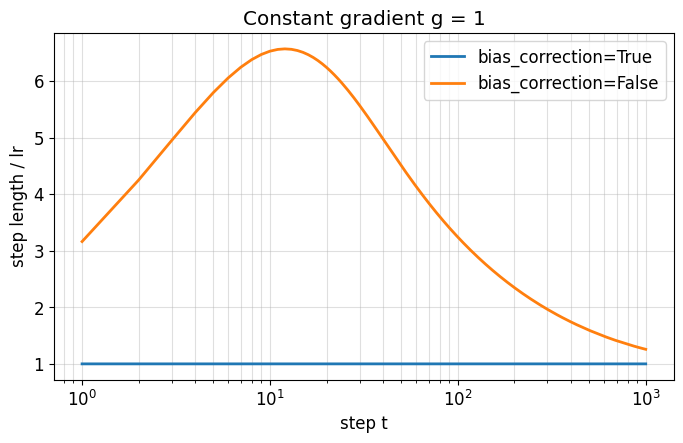

In [309]:
plt.figure(figsize=(8, 4.5))
for bc, lengths in bc_runs.items():
    plt.semilogx(range(1, len(lengths) + 1), lengths / lr, linewidth=2, label=f'bias_correction={bc}')
plt.xlabel('step t')
plt.ylabel('step length / lr')
plt.title('Constant gradient g = 1')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Выведите длину шага без bias correction при $g_t \equiv 1$ как функцию $t$ и сравните с выводом ячейки. Чем это опасно в начале обучения?

**Ответ.** Моменты стартуют с нуля, и при $g_t \equiv 1$ это просто геометрические суммы:
$$
m_t = (1 - \beta_1) \sum_{i=0}^{t-1} \beta_1^i = 1 - \beta_1^t, \qquad v_t = 1 - \beta_2^t.
$$
Без bias correction шаг равен
$$
\frac{\Delta\theta_t}{\eta} = \frac{1 - \beta_1^t}{\sqrt{1 - \beta_2^t} + \epsilon} \approx \frac{1 - 0.9^t}{\sqrt{1 - 0.999^t}}.
$$
Проверка по ячейке: при $t = 1$ это $0.1 / \sqrt{0.001} = 3.16$, при $t = 10$ — $0.651 / 0.0998 = 6.53$, при $t = 100$ — $1.0 / 0.309 = 3.24$, при $t = 1000$ — $1 / 0.795 = 1.26$. Всё совпадает с выводом. Максимум 6.57 приходится на $t = 12$, а к 1 шаг подходит только через несколько тысяч шагов. С bias correction $\hat m_t = \hat v_t = 1$, и шаг ровно $\eta$ с первой итерации.

Откуда перекос: $v_t$ из-за $\beta_2 = 0.999$ «помнит» нулевую инициализацию гораздо дольше, чем $m_t$ с $\beta_1 = 0.9$. Знаменатель занижен сильнее числителя, и шаг раздувается. Опасно это тем, что первые сотни шагов эффективный lr в 3–6.5 раз больше заданного, и как раз тогда, когда веса случайные, градиенты большие и шумные, а ландшафт крутой. Можно сразу улететь в область с огромным loss или словить NaN. Если lr подбирали под нормальный режим, то в начале он фактически выходит за допустимые пределы. Bias correction это убирает, частично ту же проблему решает и warmup.

## 3.3 Cosine schedule (0.5 балла)

Множитель learning rate для `LambdaLR` (шаг $t$ считается с нуля, $T$ — число шагов, $r$ — доля от начального lr в конце):
$$
\lambda(t) = r + (1 - r)\, \frac{1 + \cos\big(\pi \min(1,\, t / T)\big)}{2}.
$$
На интервале от нулевого шага до $T$ это то же расписание, что `CosineAnnealingLR(T_max=T, eta_min=r·lr)`; после $T$ наша функция остаётся на минимуме, в отличие от продолжения cosine в PyTorch; проверка — совпадение learning rate по шагам с вашим `MyAdamW`.

**Оценивание:** код — 0.3; эксперимент — 0; объяснение — 0.2 балла.

In [310]:
def cosine_lr(step, total_steps, min_ratio=0.0):
    progress = min(1.0, step / total_steps)
    return min_ratio + (1 - min_ratio) * (1 + math.cos(math.pi * progress)) / 2

In [311]:
T, r, base_lr = 500, 0.1, 3e-3
lam = [cosine_lr(t, T, r) for t in range(T + 1)]
assert abs(lam[0] - 1) < 1e-12 and abs(lam[T] - r) < 1e-12 and abs(cosine_lr(2 * T, T, r) - r) < 1e-12
assert abs(lam[T // 2] - (r + (1 - r) / 2)) < 1e-9


def lr_trace(make_scheduler, steps=T):
    p = torch.zeros(1, requires_grad=True)
    optimizer = MyAdamW([p], lr=base_lr)
    scheduler = make_scheduler(optimizer)
    trace = []
    for _ in range(steps):
        trace.append(scheduler.get_last_lr()[0])
        optimizer.step()
        scheduler.step()
    return np.array(trace)


mine = lr_trace(lambda opt: torch.optim.lr_scheduler.LambdaLR(opt, lambda t: cosine_lr(t, T, r)))
ref = lr_trace(lambda opt: torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=T, eta_min=r * base_lr))
assert np.allclose(mine, ref, rtol=1e-6, atol=1e-12)

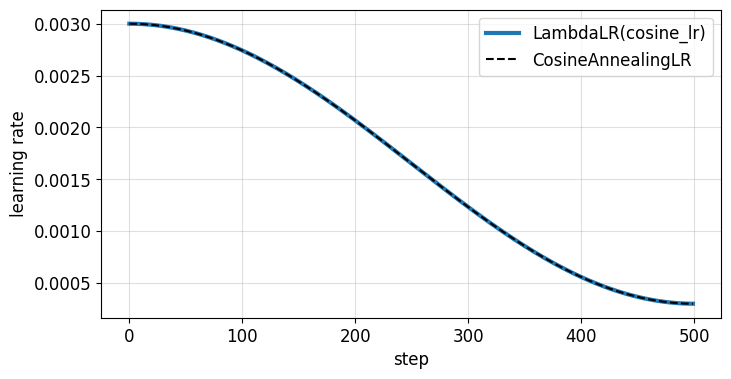

In [312]:
plt.figure(figsize=(8, 4))
plt.plot(mine, linewidth=3, label='LambdaLR(cosine_lr)')
plt.plot(ref, 'k--', linewidth=1.5, label='CosineAnnealingLR')
plt.xlabel('step')
plt.ylabel('learning rate')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Зачем уменьшать learning rate к концу обучения, если оптимизатор и так адаптивный? Что происходит со стохастическим методом при постоянном шаге около минимума?

**Ответ.** Адаптивность Adam не уменьшает шаг около минимума. Он делит градиент на его собственную RMS, поэтому шаг по каждой координате остаётся порядка $\eta$, какой бы маленький ни был градиент. Около минимума истинный градиент почти ноль, и в оценке по батчу остаётся в основном шум. Но $\hat m / \sqrt{\hat v}$ от чистого шума не равно нулю: усреднение $m$ по ~10 шагам гасит шум лишь частично, и параметры продолжают дёргаться на величину, сравнимую с $\eta$. Адаптивность подстраивает масштаб под разные координаты, но не знает, что пора остановиться. Это решает только расписание.

Стохастический метод с постоянным шагом в минимум не сходится. Он выходит на стационарное блуждание вокруг минимума, и размер этого «облака» растёт с шагом и с дисперсией шума градиента: для SGD средний избыток loss над минимумом примерно пропорционален $\eta \sigma^2$. Loss выходит на плато выше минимума и там шумит. Уменьшение lr к концу сжимает это облако, и модель оседает ближе ко дну. Поэтому в конце cosine-расписания loss и accuracy обычно заметно улучшаются. А большой lr в начале нужен, чтобы быстро пройти путь до этой области.

---
# 4. ResNet на CIFAR-10

CIFAR-10: 50 000 + 10 000 цветных картинок $32 \times 32$, 10 классов. Весь датасет хранится одним `uint8`-тензором на `device` (≈ 180 MB), нормализация делается на лету над батчем.

In [313]:


N_TRAIN = 10_000 if FAST_MODE else 50_000
N_TEST = 2_000 if FAST_MODE else 10_000

cifar_train = datasets.CIFAR10(DATA_ROOT, train=True, download=True)
cifar_test = datasets.CIFAR10(DATA_ROOT, train=False, download=True)
CIFAR_CLASSES = cifar_train.classes


def to_tensors(ds, n):
    X = torch.from_numpy(ds.data[:n]).permute(0, 3, 1, 2).contiguous()   # uint8 (N, 3, 32, 32)
    return X.to(device), torch.tensor(ds.targets[:n]).to(device)


X_train, Y_train = to_tensors(cifar_train, N_TRAIN)
X_test, Y_test = to_tensors(cifar_test, N_TEST)
CIFAR_MEAN = (X_train.float() / 255).mean(dim=(0, 2, 3))
CIFAR_STD = (X_train.float() / 255).std(dim=(0, 2, 3))
X_train.shape, X_test.shape, CIFAR_MEAN, CIFAR_STD

(torch.Size([50000, 3, 32, 32]),
 torch.Size([10000, 3, 32, 32]),
 tensor([0.4914, 0.4822, 0.4465], device='cuda:0'),
 tensor([0.2470, 0.2435, 0.2616], device='cuda:0'))

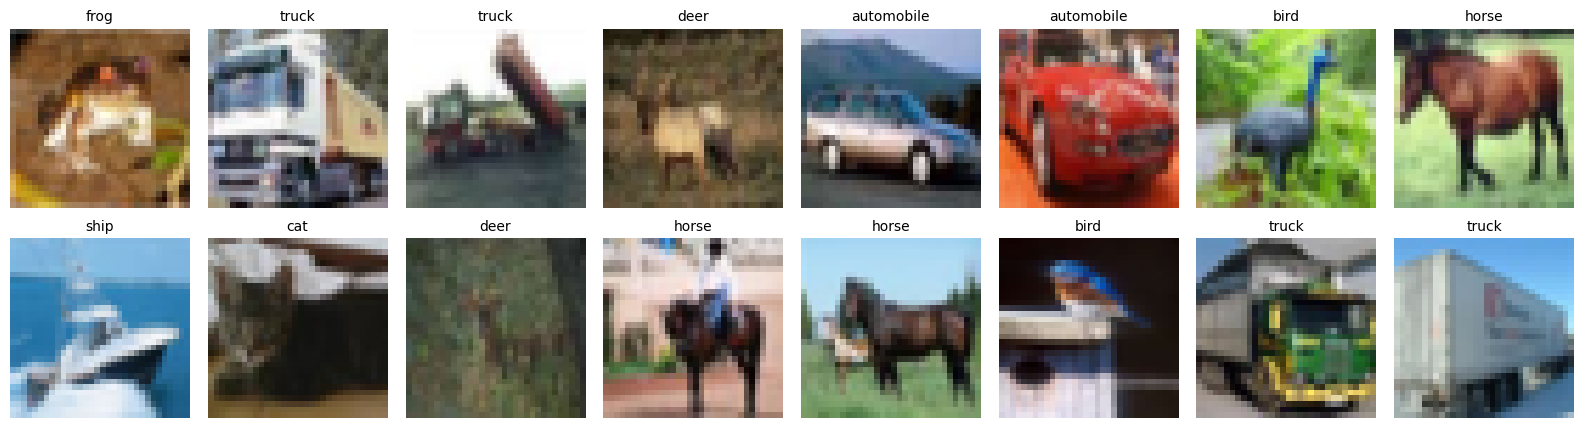

In [314]:
def normalize(x_uint8):
    return (x_uint8.float() / 255 - CIFAR_MEAN[:, None, None]) / CIFAR_STD[:, None, None]


fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.flat, range(16)):
    ax.imshow(X_train[i].permute(1, 2, 0).cpu())
    ax.set_title(CIFAR_CLASSES[Y_train[i]], fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4.1 ResNet для CIFAR (1 балл)

ResNet для CIFAR из §4.2 статьи [Deep Residual Learning for Image Recognition](https://arxiv.org/pdf/1512.03385), He et al., 2015: stem — свёртка $3 \times 3$ на 16 каналов с BN и ReLU; затем три стадии по $n$ блоков шириной 16, 32 и 64; в конце global average pooling и `Linear(64, 10)`. Глубина $6n + 2$. Первый блок второй и третьей стадии — со stride 2.

Блок (свёртки $3 \times 3$ без bias):
$$
F(x) = \mathrm{BN}\Big(\mathrm{Conv}\big(\mathrm{ReLU}(\mathrm{BN}(\mathrm{Conv}(x)))\big)\Big), \qquad y = \mathrm{ReLU}\big(F(x) + \mathrm{shortcut}(x)\big).
$$
Shortcut — `Identity`, а при смене формы (stride 2 или другое число каналов) — свёртка $1 \times 1$ с тем же stride и BN после неё. Флаги:

- `residual=False` — plain-сеть: сложения нет, shortcut-модулей нет;
- `separable=True` — каждая $3 \times 3$ свёртка блоков заменена на depthwise $3 \times 3$ и следующую за ней pointwise $1 \times 1$, обе без bias; stem остаётся обычным.

**Оценивание:** код — 1; эксперимент — 0; объяснение — 0 балла.

In [315]:
def conv3x3(c_in, c_out, stride=1, separable=False):
    if not separable:
        return nn.Conv2d(c_in, c_out, 3, stride=stride, padding=1, bias=False)
    depthwise = nn.Conv2d(c_in, c_in, 3, stride=stride, padding=1, groups=c_in, bias=False)
    pointwise = nn.Conv2d(c_in, c_out, 1, bias=False)
    return nn.Sequential(depthwise, pointwise)


class Block(nn.Module):
    def __init__(self, c_in, c_out, stride=1, residual=True, separable=False):
        super().__init__()
        self.residual = residual
        self.body = nn.Sequential(
            conv3x3(c_in, c_out, stride, separable), nn.BatchNorm2d(c_out), nn.ReLU(),
            conv3x3(c_out, c_out, 1, separable), nn.BatchNorm2d(c_out),
        )
        if not residual:
            return
        is_shape_changed = stride != 1 or c_in != c_out
        self.shortcut = (nn.Sequential(nn.Conv2d(c_in, c_out, 1, stride=stride, bias=False), nn.BatchNorm2d(c_out))
                         if is_shape_changed else nn.Identity())

    def forward(self, x):
        out = self.body(x)
        if self.residual:
            out = out + self.shortcut(x)
        return F.relu(out)


class ResNetCIFAR(nn.Module):
    def __init__(self, depth=20, residual=True, separable=False, widths=(16, 32, 64), n_classes=10):
        super().__init__()
        assert (depth - 2) % 6 == 0
        blocks_per_stage = (depth - 2) // 6
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, padding=1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU())

        blocks, c_in = [], widths[0]
        for stage, width in enumerate(widths):
            for i in range(blocks_per_stage):
                stride = 2 if stage > 0 and i == 0 else 1
                blocks.append(Block(c_in, width, stride, residual, separable))
                c_in = width
        self.blocks = nn.Sequential(*blocks)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(widths[-1], n_classes))

    def forward(self, x):
        return self.head(self.blocks(self.stem(x)))

In [316]:
x = torch.randn(2, 3, 32, 32)
for depth in [8, 20, 56]:
    for kwargs in [dict(), dict(residual=False), dict(separable=True)]:
        assert ResNetCIFAR(depth, **kwargs)(x).shape == (2, 10), (depth, kwargs)
assert n_params(ResNetCIFAR(20)) == 272_474
assert n_params(ResNetCIFAR(20, residual=False)) == 269_722
{name: n_params(ResNetCIFAR(depth, **kwargs)) for name, depth, kwargs in
 [('ResNet-20', 20, {}), ('ResNet-56', 56, {}), ('ResNet-20, separable', 20, dict(separable=True))]}

{'ResNet-20': 272474, 'ResNet-56': 855770, 'ResNet-20, separable': 40522}

## 4.2 Обучение (2 балла)

Реализуйте `train_cifar`: `MyAdamW` из 3.2 (weight decay только для параметров с `ndim > 1`), `LambdaLR` с `cosine_lr` из 3.3 до нуля за всё обучение ($r = 0$), cross-entropy, батч 256. После каждой эпохи — test accuracy. Вернуть историю `dict(train_loss, test_acc)` по эпохам.

Для ResNet-20 при `FAST_MODE = False` ориентир test accuracy — `TARGET_ACC` за `EPOCHS` эпох с `LR`. Это диагностический ориентир, не жёсткий порог балла: при заметном отставании проверьте normalisation, train/eval, scheduler и loss и опишите результат. Аугментации в этом протоколе нет. Каждый батч нормируйте через `normalize`; `scheduler.step()` вызывается после каждого `optimizer.step()`, `train_loss` — среднее по объектам за эпоху.

Test используется для учебных кривых с заранее фиксированными гиперпараметрами. Если выбираете гиперпараметры самостоятельно, выделите validation из train; test не используйте для выбора конфигурации.

**Оценивание:** код — 1.1; эксперимент — 0.6; объяснение — 0.3 балла.

In [317]:
EPOCHS = 3 if FAST_MODE else 20
LR = 0.003
TARGET_ACC = 0.82


def make_param_groups(model, weight_decay):
    decayed = [p for p in model.parameters() if p.ndim > 1]
    not_decayed = [p for p in model.parameters() if p.ndim <= 1]
    return [dict(params=decayed, weight_decay=weight_decay), dict(params=not_decayed, weight_decay=0.0)]


def train_cifar(model, epochs, lr, weight_decay=0.05, batch_size=256, log=True):
    model = model.to(device)
    history = dict(train_loss=[], test_acc=[])
    start = time.time()
    optimizer = MyAdamW(make_param_groups(model, weight_decay), lr=lr)
    total_steps = epochs * math.ceil(len(X_train) / batch_size)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda step: cosine_lr(step, total_steps, 0.0))

    for epoch in range(epochs):
        model.train()
        loss_sum = 0.0
        for xb, yb in iterate_batches(X_train, Y_train, batch_size, transform=normalize):
            loss = F.cross_entropy(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            scheduler.step()
            loss_sum += loss.item() * len(yb)

        history['train_loss'].append(loss_sum / len(X_train))
        history['test_acc'].append(accuracy(predict_logits(model, X_test, transform=normalize), Y_test))
        if log:
            print(f'epoch {epoch + 1:>3}/{epochs}  train loss {history["train_loss"][-1]:.4f}  '
                  f'test acc {history["test_acc"][-1]:.4f}  {time.time() - start:.0f}s')
    return history

In [318]:
set_seed(0)
resnet20 = ResNetCIFAR(20)
started = time.perf_counter()
history = train_cifar(resnet20, EPOCHS, LR)
RUN_TIMES['cifar_resnet20_seconds'] = time.perf_counter() - started
history_cifar = history
test_acc = history['test_acc'][-1]
train_acc = accuracy(predict_logits(resnet20, X_train[:10_000], transform=normalize), Y_train[:10_000])
if not FAST_MODE and test_acc < TARGET_ACC:
    print(f'Accuracy {test_acc:.3f} ниже ориентира {TARGET_ACC:.2f}: проверьте протокол и обсудите результат.')
{'train acc': train_acc, 'test acc': test_acc}

epoch   1/20  train loss 1.4127  test acc 0.5579  14s
epoch   2/20  train loss 0.9599  test acc 0.6298  28s
epoch   3/20  train loss 0.7933  test acc 0.6240  41s
epoch   4/20  train loss 0.6727  test acc 0.7378  55s
epoch   5/20  train loss 0.5794  test acc 0.7431  68s
epoch   6/20  train loss 0.5101  test acc 0.7321  81s
epoch   7/20  train loss 0.4491  test acc 0.7935  94s
epoch   8/20  train loss 0.3933  test acc 0.7963  107s
epoch   9/20  train loss 0.3410  test acc 0.7912  120s
epoch  10/20  train loss 0.2914  test acc 0.7767  133s
epoch  11/20  train loss 0.2387  test acc 0.8138  146s
epoch  12/20  train loss 0.1827  test acc 0.8046  159s
epoch  13/20  train loss 0.1352  test acc 0.8166  172s
epoch  14/20  train loss 0.0934  test acc 0.8209  185s
epoch  15/20  train loss 0.0576  test acc 0.8311  198s
epoch  16/20  train loss 0.0346  test acc 0.8314  211s
epoch  17/20  train loss 0.0247  test acc 0.8319  224s
epoch  18/20  train loss 0.0181  test acc 0.8331  237s
epoch  19/20  tra

{'train acc': 0.9994999766349792, 'test acc': 0.8325999975204468}

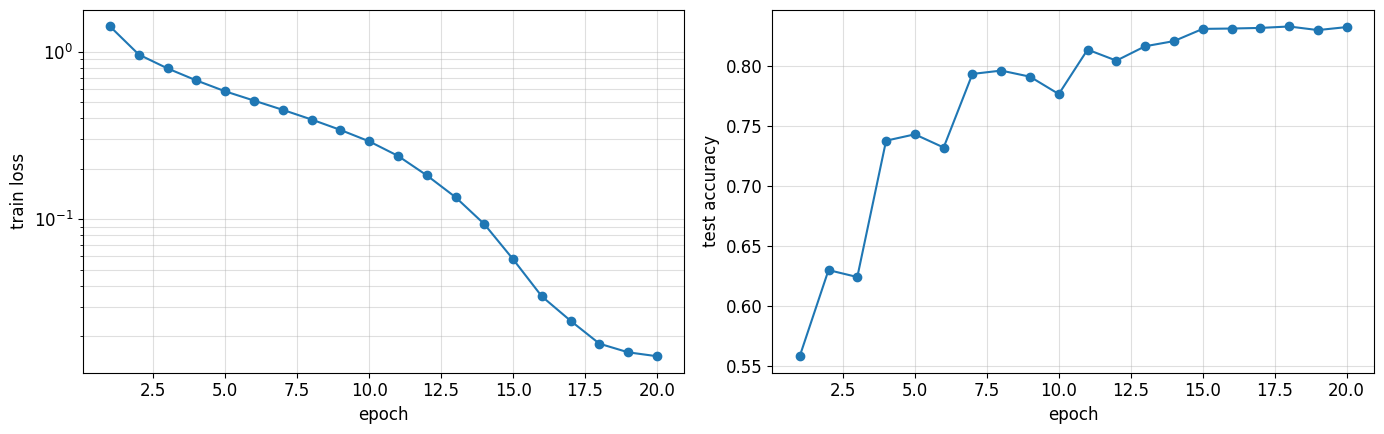

In [319]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
epochs_axis = range(1, len(history['test_acc']) + 1)
ax1.semilogy(epochs_axis, history['train_loss'], 'o-')
ax1.set_ylabel('train loss')
ax2.plot(epochs_axis, history['test_acc'], 'o-')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
plt.tight_layout()
plt.show()

**Вопрос.** Какой разрыв между train и test accuracy в конце обучения? Как ведут себя train loss и test accuracy на последних эпохах, когда learning rate уходит к нулю?

**Ответ.** Разрыв большой: train accuracy 99.98% (на первых 10 000 объектах), test 82.8%, то есть около 17 п.п. Сеть фактически запомнила обучающую выборку. Неудивительно: аугментаций нет, 20 эпох по одним и тем же картинкам, а 270 тысяч параметров на 50 тысяч картинок хватает. Ориентир 0.82 пройден.

Пока lr большой, test accuracy сильно скачет: на 7-й эпохе 0.711 после 0.756 на 6-й, на 10-й 0.759 после 0.802. Когда lr уходит к нулю, скачки пропадают. Train loss в конце продолжает падать — с 0.054 на 15-й эпохе до 0.014 на 20-й, почти в 4 раза. А test accuracy с 14-й эпохи стоит на месте около 0.83 (0.828, 0.826, 0.830, 0.829, 0.831, 0.829, 0.828). Значит, последние эпохи уходят на дожимание уверенности на train, а на test это уже не влияет. Но и не вредит: явного переобучения в смысле падения test accuracy не видно, просто плато. Важная оговорка: всё это один запуск с одним seed, так что колебания в третьем знаке на плато — это шум.

## 4.3 Абляции (1.5 балла)

Сравните **plain-20 и plain-56** при одинаковых `ABL_EPOCHS` и `LR`. Это два дополнительных обучения. Результат — `ablation[name] = dict(params, train_acc, test_acc, minutes, history)`, где `train_acc` считается на первых 10 000 объектах train, а `history` возвращается `train_cifar`.

Перед каждой конфигурацией вызовите `set_seed(0)`. Проверяем гипотезу: увеличение глубины plain-сети может затруднить оптимизацию даже на train ([He et al., 2015](https://arxiv.org/pdf/1512.03385)). Это не обещание, что при данном optimizer и коротком бюджете эффект обязательно появится. Отличайте результат «хуже на train» от «лучше на train, хуже на test». Для сравнения с residual-сетями нужен одинаковый протокол; основной ResNet-20 обучался дольше, его финальную accuracy нельзя напрямую трактовать как контроль этого опыта.

**Оценивание:** код — 0.2; эксперимент — 0.7; объяснение — 0.6 балла.

In [320]:
ABL_EPOCHS = 2 if FAST_MODE else 10
ABLATIONS = {
    'plain-20': dict(depth=20, residual=False),
    'plain-56': dict(depth=56, residual=False),
}

In [321]:
ablation = {}
for name, config in ABLATIONS.items():
    set_seed(0)
    model = ResNetCIFAR(**config)
    started = time.perf_counter()
    history = train_cifar(model, ABL_EPOCHS, LR)
    seconds = time.perf_counter() - started
    RUN_TIMES[f'ablation_{name}_seconds'] = seconds
    train_acc = accuracy(predict_logits(model, X_train[:10_000], transform=normalize), Y_train[:10_000])
    ablation[name] = dict(params=n_params(model), train_acc=train_acc, test_acc=history['test_acc'][-1],
                          minutes=seconds / 60, history=history)

print(f'{"model":<22}{"params":>9}{"train acc":>11}{"test acc":>10}{"minutes":>9}')
for name, res in ablation.items():
    print(f'{name:<22}{res["params"]:>9,}{res["train_acc"]:>11.4f}{res["test_acc"]:>10.4f}{res["minutes"]:>9.1f}')

epoch   1/10  train loss 1.6629  test acc 0.3879  13s
epoch   2/10  train loss 1.2801  test acc 0.5583  25s
epoch   3/10  train loss 1.0679  test acc 0.6090  38s
epoch   4/10  train loss 0.9174  test acc 0.6738  50s
epoch   5/10  train loss 0.8027  test acc 0.6866  63s
epoch   6/10  train loss 0.7048  test acc 0.7236  75s
epoch   7/10  train loss 0.6180  test acc 0.7492  87s
epoch   8/10  train loss 0.5430  test acc 0.7704  100s
epoch   9/10  train loss 0.4868  test acc 0.7793  113s
epoch  10/10  train loss 0.4612  test acc 0.7816  125s
epoch   1/10  train loss 1.9673  test acc 0.1808  37s
epoch   2/10  train loss 1.8164  test acc 0.2940  75s
epoch   3/10  train loss 1.7020  test acc 0.3607  112s
epoch   4/10  train loss 1.6175  test acc 0.3494  149s
epoch   5/10  train loss 1.5296  test acc 0.4012  187s
epoch   6/10  train loss 1.4385  test acc 0.4343  224s
epoch   7/10  train loss 1.3420  test acc 0.5035  261s
epoch   8/10  train loss 1.2434  test acc 0.5443  299s
epoch   9/10  train

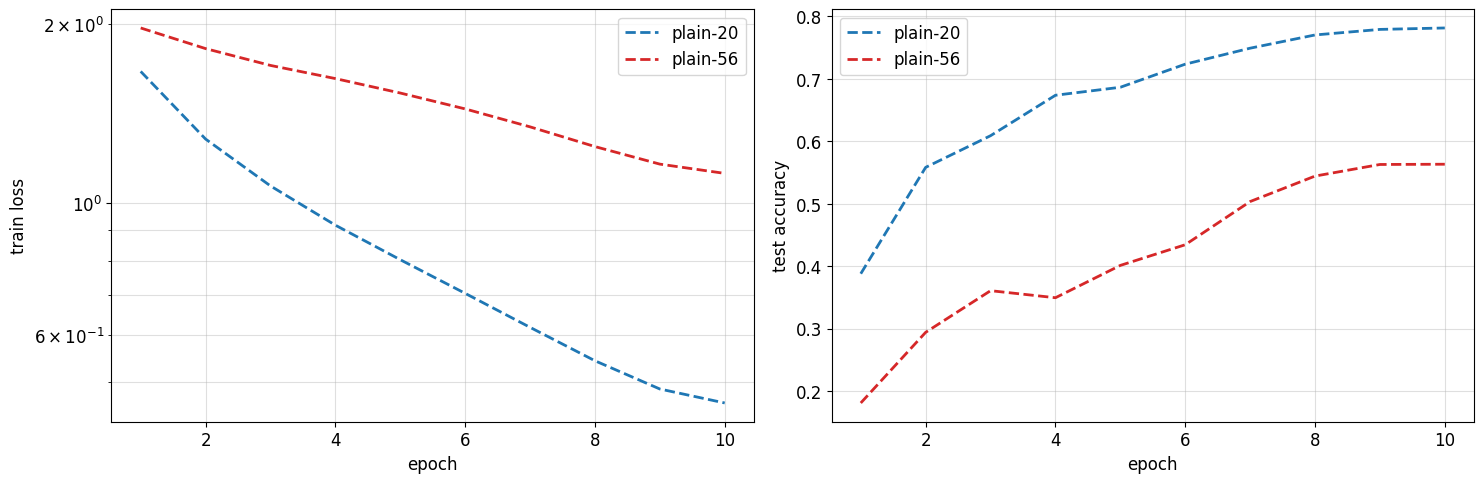

In [322]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
for name in ABLATIONS:
    hist = ablation[name]['history']
    style = '-' if name.startswith('ResNet') else '--'
    color = 'tab:blue' if '20' in name else 'tab:red'
    epochs_axis = range(1, len(hist['train_loss']) + 1)
    ax1.semilogy(epochs_axis, hist['train_loss'], style, color=color, linewidth=2, label=name)
    ax2.plot(epochs_axis, hist['test_acc'], style, color=color, linewidth=2, label=name)
ax1.set_ylabel('train loss')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
    ax.legend()
plt.tight_layout()
plt.show()

**Вопрос.** Есть ли в вашем прогоне ухудшение train loss при увеличении глубины? Как изменились train и test accuracy? Какие наблюдения говорят о трудностях оптимизации, а какие — о переобучении? Если ухудшения на train нет, напишите это. Предложите **один** следующий контрольный эксперимент, позволяющий проверить ваше объяснение; запускать его не требуется.

**Ответ.** Да, ухудшение на train есть, и сильное. При одинаковом протоколе (10 эпох, тот же lr и seed) plain-56 закончил с train loss 1.11, а plain-20 — с 0.46. Train accuracy 60.3% против 85.3%, test 57.1% против 77.9%. Причём plain-56 хуже не только в конце: его train loss выше на каждой эпохе, начиная с первой (1.97 против 1.67). Параметров у него в 3 раза больше (853 тыс. против 270 тыс.), то есть ёмкости хватает с запасом, а train он подогнать не может.

Это похоже именно на трудности оптимизации, а не на переобучение. При переобучении глубокая сеть была бы лучше на train и хуже на test. Здесь она хуже на обоих, и разрыв train–test у неё даже меньше: 3.3 п.п. против 7.4 п.п. у plain-20. Глубокая сеть недообучена, ей не на чем переобучаться. Явных признаков переобучения нет ни у одной из сетей: test accuracy у обеих к концу растёт или стоит.

Ограничение: бюджет короткий. По этим данным нельзя отличить «plain-56 вообще не может обучиться» от «plain-56 учится медленнее и за 10 эпох просто не успел». Кроме того, это один seed.

Контрольный эксперимент: обучить ResNet-56 (`residual=True`) по тому же протоколу. Глубина и число параметров у него почти те же, отличаются только shortcut-связи. Если его train loss окажется не хуже, чем у plain-20, значит, мешает не глубина и не размер модели, а то, что plain-сеть такой глубины плохо оптимизируется. Если ResNet-56 тоже отстанет, то дело скорее в нехватке эпох для большой модели.

---
# 5. Атаки

Модель — маленькая CNN на FashionMNIST (пиксели в $[0, 1]$, без `Normalize`). В финальном режиме модель учится на полном train, а серии атак идут по фиксированным 1000 test-объектам. Раздел 5.1 обязателен; далее выполняется только ветка, выбранная в `ATTACK_TRACK`. Все модели во время оценки атак находятся в `eval()`. Метрики на такой подвыборке имеют sampling noise; близкие результаты не следует ранжировать как надёжное преимущество.

In [323]:
N_FM_TRAIN = 12_000 if FAST_MODE else 60_000
N_FM_TEST = 256 if FAST_MODE else 1_000
FM_EPOCHS = 2 if FAST_MODE else 5

fm_train = datasets.FashionMNIST(DATA_ROOT, train=True, download=True)
fm_test = datasets.FashionMNIST(DATA_ROOT, train=False, download=True)
FM_CLASSES = fm_train.classes


def fm_tensors(ds, n):
    return (ds.data[:n, None].float() / 255).to(device), ds.targets[:n].to(device)


XF_train, YF_train = fm_tensors(fm_train, N_FM_TRAIN)
XF_test, YF_test = fm_tensors(fm_test, N_FM_TEST)
XF_train.shape, XF_test.shape

(torch.Size([60000, 1, 28, 28]), torch.Size([1000, 1, 28, 28]))

Модель, обучение и атаки FGSM и PGD в $L_\infty$ — готовый код:

In [324]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Linear(64 * 7 * 7, n_classes)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


def train_fm(model, epochs=FM_EPOCHS, lr=1e-3):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        model.train()
        for x, y in iterate_batches(XF_train, YF_train, 128):
            loss = F.cross_entropy(model(x), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    model.eval()
    return model

In [325]:
def fgsm_attack(model, x, y, eps):
    x = x.detach()
    x_adv = x.clone().requires_grad_(True)
    with torch.enable_grad():
        grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
    return (x + eps * grad.sign()).clamp(0, 1).detach()


def pgd_attack(model, x, y, eps, alpha, steps, random_start=True):
    x = x.detach()
    x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1) if random_start else x.clone()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        x_adv = x_adv.detach() + alpha * grad.sign()
        x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)
    return x_adv.detach()


def pgd(model, x, y, eps, steps=20):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / steps, steps=steps)


def attack_accuracy(model, X, Y, attack=None, batch_size=500, **attack_kwargs):
    model.eval()
    correct = 0
    for i in range(0, len(X), batch_size):
        x, y = X[i:i + batch_size], Y[i:i + batch_size]
        if attack is not None:
            x = attack(model, x, y, **attack_kwargs)
        with torch.no_grad():
            correct += (model(x).argmax(dim=1) == y).sum().item()
    return correct / len(X)


def assert_no_param_grads(model):
    assert all(p.grad is None for p in model.parameters())

In [326]:
set_seed(0)
started = time.perf_counter()
model_a = train_fm(SmallCNN())
RUN_TIMES['fashion_standard_seconds'] = time.perf_counter() - started
model_a.zero_grad(set_to_none=True)
{'clean': attack_accuracy(model_a, XF_test, YF_test),
 'FGSM, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, fgsm_attack, eps=0.1),
 'PGD-20, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)}

{'clean': 0.912, 'FGSM, eps=0.1': 0.081, 'PGD-20, eps=0.1': 0.003}

## 5.1 PGD в $L_2$ (1 балл)

Ограничение $\|\delta\|_2 \le \varepsilon$. Линеаризация loss (как при выводе FGSM) даёт шаг по нормированному градиенту, а проекция на шар — масштабирование:
$$
x' = x^{(k)} + \alpha\, \frac{g}{\|g\|_2}, \qquad
\delta = x' - x, \qquad
x^{(k+1)} = \mathrm{clip}_{[0, 1]}\Big(x + \delta \cdot \min\big(1,\, \tfrac{\varepsilon}{\|\delta\|_2}\big)\Big).
$$
Нормы — по каждой картинке отдельно. Старт из $x$ (без random start).

**Оценивание:** код — 0.6; эксперимент — 0.2; объяснение — 0.2 балла.

In [327]:
def per_image_l2_norm(t):
    return t.flatten(1).norm(dim=1).clamp_min(1e-12).view(-1, *[1] * (t.dim() - 1))


def pgd_l2(model, x, y, eps, alpha, steps):
    x = x.detach()
    x_adv = x.clone()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        x_step = x_adv.detach() + alpha * grad / per_image_l2_norm(grad)
        delta = x_step - x
        delta = delta * torch.clamp(eps / per_image_l2_norm(delta), max=1.0)
        x_adv = (x + delta).clamp(0, 1)
    return x_adv.detach()

In [328]:
x, y = XF_test[:500], YF_test[:500]
eps2 = 2.0
x_adv = pgd_l2(model_a, x, y, eps=eps2, alpha=2.5 * eps2 / 20, steps=20)
assert (x_adv - x).flatten(1).norm(dim=1).max() <= eps2 + 1e-4
assert x_adv.min() >= 0 and x_adv.max() <= 1 and not x_adv.requires_grad
assert_no_param_grads(model_a)
acc_clean, acc_l2 = attack_accuracy(model_a, x, y), attack_accuracy(model_a, x_adv, y)
print(f'Падение accuracy под PGD-L2: {acc_clean - acc_l2:.3f}; маленькое падение требует диагностики.')
acc_clean, acc_l2

Падение accuracy под PGD-L2: 0.916; маленькое падение требует диагностики.


(0.916, 0.0)

In [329]:
def pgd_l2_20(model, x, y, eps):
    return pgd_l2(model, x, y, eps, alpha=2.5 * eps / 20, steps=20)


eps_l2 = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0]
acc_l2 = [attack_accuracy(model_a, XF_test, YF_test, pgd_l2_20, eps=e) for e in eps_l2]
acc_linf = attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)
dict(zip(eps_l2, acc_l2)), acc_linf

({0.0: 0.912,
  0.5: 0.461,
  1.0: 0.089,
  1.5: 0.008,
  2.0: 0.0,
  3.0: 0.0,
  4.0: 0.0},
 0.002)

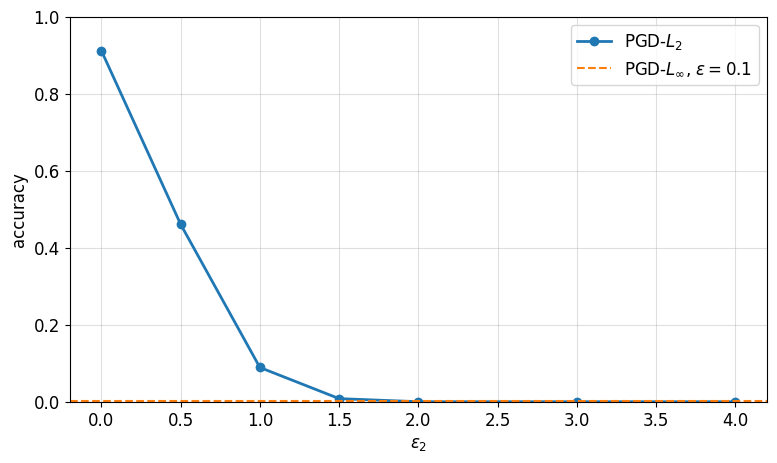

In [330]:
plt.figure(figsize=(9, 5))
plt.plot(eps_l2, acc_l2, 'o-', linewidth=2, label=r'PGD-$L_2$')
plt.axhline(acc_linf, color='tab:orange', linestyle='--', label=r'PGD-$L_\infty$, $\varepsilon = 0.1$')
plt.xlabel(r'$\varepsilon_2$')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

Возмущения обеих атак на одних картинках; $\varepsilon_2$ — ближайшая по accuracy точка проверенной сетки. Если разница велика, сравнение не следует называть сравнением при равной силе атаки. Цветовая шкала каждой карты нормирована отдельно; абсолютные нормы выведены под рисунком:

Ближайшая точка сетки: eps2=2.0, accuracy gap=0.002


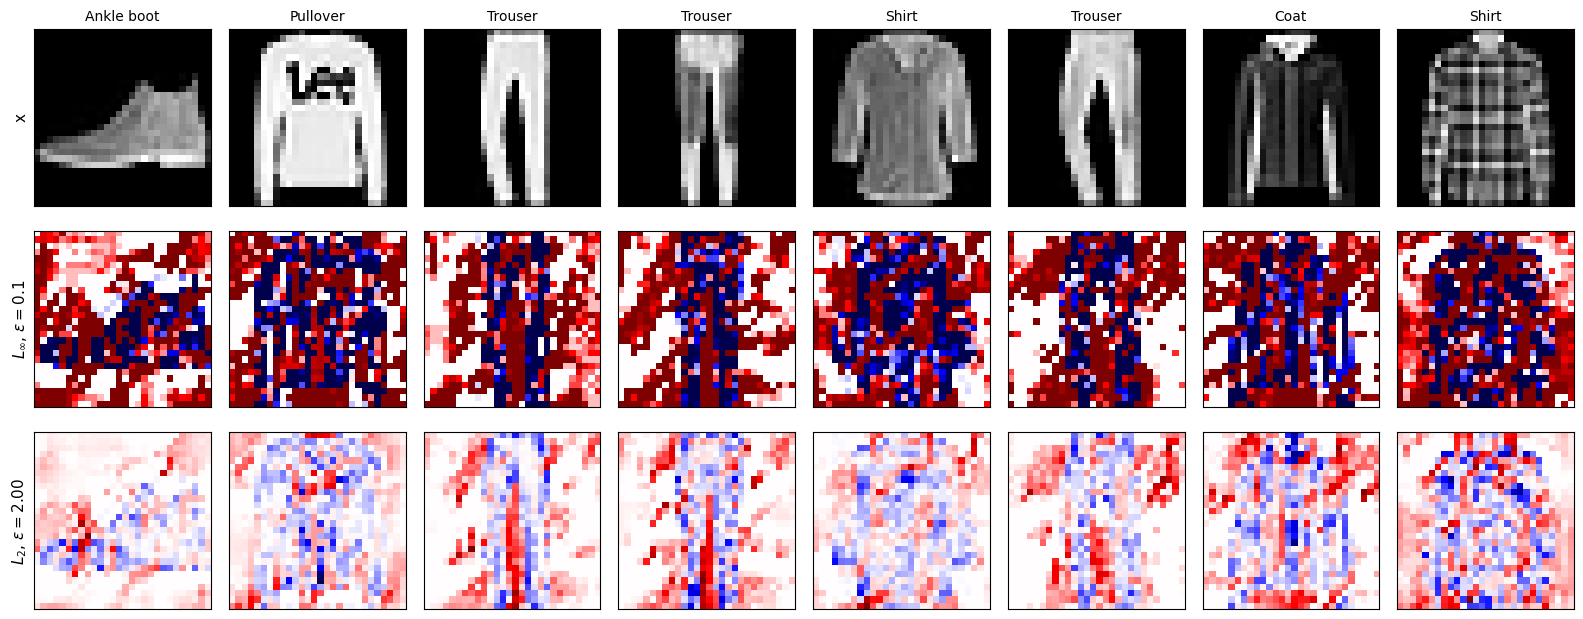

$L_\infty$, $\varepsilon=0.1$ L_inf = 0.100   L_2 = 2.127
$L_2$, $\varepsilon=2.00$    L_inf = 0.386   L_2 = 1.986


In [331]:
# Поиск ближайшей проверенной точки не предполагает монотонность конечной PGD.
match_idx = int(np.argmin(np.abs(np.asarray(acc_l2) - acc_linf)))
eps2_match = float(eps_l2[match_idx])
print(f'Ближайшая точка сетки: eps2={eps2_match}, accuracy gap={abs(acc_l2[match_idx] - acc_linf):.3f}')
x8, y8 = XF_test[:8], YF_test[:8]
torch.manual_seed(0)
deltas = {r'$L_\infty$, $\varepsilon=0.1$': pgd(model_a, x8, y8, 0.1) - x8,
          rf'$L_2$, $\varepsilon={eps2_match:.2f}$': pgd_l2_20(model_a, x8, y8, eps2_match) - x8}
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for i in range(8):
    axes[0, i].imshow(x8[i, 0].cpu(), cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title(FM_CLASSES[y8[i]], fontsize=10)
    for row, d in enumerate(deltas.values(), start=1):
        vmax = d[i].abs().max().item()
        axes[row, i].imshow(d[i, 0].cpu(), cmap='seismic', vmin=-vmax, vmax=vmax)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
for ax, label in zip(axes[:, 0], ['x'] + list(deltas)):
    ax.set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()
for name, d in deltas.items():
    print(f'{name:<28} L_inf = {d.abs().amax(dim=(1, 2, 3)).mean():.3f}   L_2 = {d.flatten(1).norm(dim=1).mean():.3f}')

**Вопрос.** Какая точка сетки $\varepsilon_2$ ближе всего по accuracy к $L_\infty$-атаке с $\varepsilon = 0.1$ и как велик остаточный разрыв? Какова $L_2$-норма самого $L_\infty$-возмущения? Где сосредоточено $L_2$-возмущение на ваших изображениях и как это связано с нормированным градиентом?

**Ответ.** Ближе всего $\varepsilon_2 = 2.0$: accuracy 0.000 против 0.004 у PGD-$L_\infty$ с $\varepsilon = 0.1$, разрыв 0.004. Соседняя $\varepsilon_2 = 1.5$ даёт 0.010, разрыв 0.006, почти так же близко. На 1000 картинках это разница в 4–6 объектов, то есть шум. По этой сетке можно сказать только, что «равная» $\varepsilon_2$ где-то между 1.0 (accuracy ещё 0.090) и 2.0, скорее около 1.5–2.

$L_2$-норма самого $L_\infty$-возмущения — 2.12. Если бы все $28 \cdot 28 = 784$ пикселя сдвинулись ровно на $\pm 0.1$, вышло бы $0.1 \cdot 28 = 2.8$. Значит, атака насыщает большую часть пикселей, кроме тех, где мешает клиппинг в $[0, 1]$: чёрный фон можно только осветлить, и на карте он почти весь красный. По $L_2$ это даже немного больше, чем у $L_2$-атаки (1.99), а сила атаки примерно та же. Обратная картина у $L_2$-атаки: её $L_\infty$-норма 0.398, то есть отдельные пиксели она двигает в 4 раза сильнее, чем позволяет $L_\infty$-бюджет. Каждая атака экономна в своей норме и расточительна в чужой.

На картинках $L_\infty$-возмущение равномерное — почти каждый пиксель на пределе $\pm\varepsilon$. $L_2$-возмущение сосредоточено: основная масса на контурах и внутри силуэта, особенно в местах, которые отличают похожие классы. Например, у брюк это полоса между штанинами, у ботинка — нижний край и подошва. На большей части фона оно почти нулевое. Это прямое следствие шага: $L_\infty$ идёт по $\mathrm{sign}(g)$ и тратит одинаковый бюджет на каждый пиксель, а $L_2$ идёт по $g / \|g\|_2$ и сохраняет относительные величины градиента. При линеаризации оптимальное $L_2$-возмущение пропорционально $g$, поэтому бюджет уходит туда, где градиент больше, а пиксели со слабым градиентом почти не трогаются.

## 5.2 Targeted attack (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'targeted'`. Ветку 5.3 при этом можно оставить пустой.

Цель — не просто ошибка, а заданный класс $t$: минимизируем loss по целевой метке
$$
x^{(k+1)} = \Pi_{B_\infty(x, \varepsilon)}\Big[x^{(k)} - \alpha\, \mathrm{sign}\, \nabla_x L\big(f(x^{(k)}), t\big)\Big].
$$

1. Реализуйте `pgd_targeted` ($L_\infty$, random start, как `pgd_attack`).
2. Реализуйте `targeted_success_matrix`: $S[s, t]$ — доля всех картинок класса $s$, которые после атаки с целью $t$ классифицируются как $t$, включая изначально ошибочные. Верните CPU-тензор; диагональ и строки отсутствующих классов — `nan`. Обрабатывайте вход батчами не более 128 объектов, сигнатуру менять не нужно. Сопоставьте результат с готовой clean confusion matrix ниже.

**Оценивание:** код — 1; эксперимент — 0.4; объяснение — 0.6 балла.

In [332]:
if ATTACK_TRACK == 'targeted':
    def pgd_targeted(model, x, target, eps, alpha, steps):
        # ваш код
        raise NotImplementedError


    def targeted_success_matrix(model, x, y, eps, steps=20, n_classes=10):
        # ваш код
        raise NotImplementedError

In [333]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    x, y = XF_test[:1000], YF_test[:1000]
    target = (y + 1) % 10
    x_t = pgd_targeted(model_a, x, target, eps=0.1, alpha=0.0125, steps=20)
    assert (x_t - x).abs().max() <= 0.1 + 1e-6 and x_t.min() >= 0 and x_t.max() <= 1
    assert_no_param_grads(model_a)
    with torch.no_grad():
        hit_rate = (model_a(x_t).argmax(dim=1) == target).float().mean().item()
    print(f'Targeted hit rate: {hit_rate:.3f}; сравните с частотой целевого класса до атаки.')
    hit_rate

In [334]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    S = targeted_success_matrix(model_a, XF_test, YF_test, eps=0.1)
    assert S.shape == (10, 10) and torch.isnan(S.diagonal()).all()
    pred_clean = predict_logits(model_a, XF_test).argmax(1)
    clean_confusion = torch.bincount((10 * YF_test + pred_clean).cpu(), minlength=100).reshape(10, 10).float()
    clean_confusion /= clean_confusion.sum(1, keepdim=True).clamp_min(1)
    print('Clean confusion matrix (строки: true, столбцы: predicted):')
    print(np.round(clean_confusion.numpy(), 2))

    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(S, cmap='viridis', vmin=0, vmax=1)
    for s, t in itertools.product(range(10), range(10)):
        if s != t:
            ax.text(t, s, f'{S[s, t]:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if S[s, t] < 0.5 else 'black')
    ax.set_xticks(range(10), FM_CLASSES, rotation=60)
    ax.set_yticks(range(10), FM_CLASSES)
    ax.set_xlabel('target class')
    ax.set_ylabel('true class')
    plt.colorbar(im, fraction=0.046)
    plt.show()

**Вопрос.** Какие пары (истинный класс, целевой класс) атакуются легче всего, какие труднее? Симметрична ли матрица? Как это связано с тем, какие классы модель путает без атаки?

**Ответ.** 

## 5.3 Transfer (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'transfer'`. Ветку 5.2 при этом можно оставить пустой.

Black-box сценарий: атакующий не видит модель-жертву, строит атаку на своей модели и надеется, что она перенесётся. Обучите `model_b` (та же архитектура, `set_seed(1)`) и MLP с двумя скрытыми слоями по 512 нейронов и ReLU (`set_seed(2)`). Атаки FGSM и PGD-20 с $\varepsilon = 0.1$, построенные на `model_a`, проверьте на всех трёх моделях. Результат — `transfer[attack][victim] = accuracy`, атаки `'clean'`, `'FGSM'`, `'PGD-20'`, жертвы `'model A (source)'`, `'model B'`, `'MLP'`.

**Оценивание:** код — 0.6; эксперимент — 0.8; объяснение — 0.6 балла.

In [335]:
if ATTACK_TRACK == 'transfer':
    def make_mlp(hidden=512, n_classes=10):
        return nn.Sequential(nn.Flatten(), nn.Linear(28 * 28, hidden), nn.ReLU(),
                             nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, n_classes))


    def craft_on_source(source, X, Y, attack, batch_size=500, **attack_kwargs):
        source.eval()
        return torch.cat([attack(source, X[i:i + batch_size], Y[i:i + batch_size], **attack_kwargs)
                          for i in range(0, len(X), batch_size)])


    set_seed(1)
    started = time.perf_counter()
    model_b = train_fm(SmallCNN())
    RUN_TIMES['fashion_model_b_seconds'] = time.perf_counter() - started

    set_seed(2)
    started = time.perf_counter()
    mlp = train_fm(make_mlp())
    RUN_TIMES['fashion_mlp_seconds'] = time.perf_counter() - started

    victims = {'model A (source)': model_a, 'model B': model_b, 'MLP': mlp}
    torch.manual_seed(0)
    adversarial_inputs = {'clean': XF_test,
                          'FGSM': craft_on_source(model_a, XF_test, YF_test, fgsm_attack, eps=0.1),
                          'PGD-20': craft_on_source(model_a, XF_test, YF_test, pgd, eps=0.1)}
    transfer = {attack: {name: attack_accuracy(victim, X_adv, YF_test) for name, victim in victims.items()}
                for attack, X_adv in adversarial_inputs.items()}
    assert_no_param_grads(model_a)

    print(f'{"":<8}' + ''.join(f'{name:>18}' for name in transfer['clean']))
    for attack, row in transfer.items():
        print(f'{attack:<8}' + ''.join(f'{acc:>18.3f}' for acc in row.values()))

          model A (source)           model B               MLP
clean                0.912             0.900             0.864
FGSM                 0.081             0.254             0.551
PGD-20               0.003             0.152             0.558


**Вопрос.** Для каждой жертвы укажите падение accuracy относительно её собственного clean baseline. Сравните с падением на source-модели. Какая атака и на какую архитектуру переносится лучше в вашем прогоне? Предложите объяснение и укажите, почему одного seed недостаточно для общего вывода о превосходстве архитектуры или атаки.

**Ответ.** Падение accuracy относительно собственного clean:

| жертва | clean | FGSM | PGD-20 |
|---|---|---|---|
| model A (source) | 0.912 | 0.082 (−0.830) | 0.005 (−0.907) |
| model B | 0.903 | 0.262 (−0.641) | 0.159 (−0.744) |
| MLP | 0.864 | 0.555 (−0.309) | 0.550 (−0.314) |

Обе атаки переносятся, но слабее, чем работают на source. Лучше всего переносится PGD-20 на model B: падение 0.74 против 0.91 на самой A. FGSM на B даёт 0.64 против 0.83 на A. На MLP переносится гораздо хуже, около 0.31 у обеих атак. Разница между FGSM и PGD там 0.005, то есть 5 объектов из 1000 — шум.

Объяснение. Model B — та же архитектура, обученная на тех же данных, только с другим seed. Она выучивает похожие признаки и похожие границы классов, поэтому направления, вредные для A, вредны и для B. Преимущество PGD над FGSM на source (0.005 против 0.082) частично сохраняется на B (0.159 против 0.262). У MLP нет свёрток и пулинга, он смотрит на картинку по-другому, и переносится только самая общая часть возмущения. Дополнительные шаги PGD подгоняют возмущение под особенности конкретной CNN, и на MLP это уже не помогает. Поэтому PGD там не сильнее одношагового FGSM.

Почему одного seed мало. Здесь одна source-модель, одна model B и один MLP, и каждая из них — случайная реализация обучения. Насколько хорошо атака переносится между двумя конкретными сетями, заметно зависит от того, как именно они обучились. При другом seed B может оказаться ближе к A или дальше от неё, и тот же разброс может сдвинуть разницу между CNN и MLP. Плюс выборка: на 1000 объектах при accuracy около 0.5 стандартная ошибка примерно 1.6 п.п. Чтобы говорить о превосходстве архитектуры или атаки, нужно повторить опыт на нескольких seed для source и для жертв и смотреть на разброс.

---
# 6. Adversarial training

## 6.1 PGD adversarial training (2 балла)

[Towards Deep Learning Models Resistant to Adversarial Attacks](https://arxiv.org/pdf/1706.06083), Madry et al., 2017:
$$
\min_\theta\; \mathbb E_{(x, y)} \Big[\max_{\|\delta\|_\infty \le \varepsilon} L\big(f_\theta(x + \delta), y\big)\Big].
$$
На каждом батче внутренний max приближается атакой, и шаг оптимизатора делается только по adversarial-примерам, без clean-части. Модель — с нуля.

Реализуйте `adversarial_train(model, eps, attack, epochs)`: `attack(model, x, y, eps)` возвращает detached `x_adv`. Используйте `torch.optim.Adam` с переданным `lr`, batch size 128, cross-entropy только на adversarial-примерах. Генерация атаки — в `eval()`, обновление весов — в `train()`; не дифференцируйте через построение атаки. После каждой эпохи записывайте clean, FGSM и PGD-20 accuracy на `XF_test[:1000]` с тем же $\varepsilon$. Перед возвратом включите `eval()` и очистите `.grad` параметров.

В обязательной части обучается одна модель с PGD-7. FGSM и FGSM-RS из готового словаря нужны только для бонуса 7.5.

**Оценивание:** код — 1; эксперимент — 0.6; объяснение — 0.4 балла.

In [336]:
def fgsm_rs_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=1.25 * eps, steps=1, random_start=True)


def pgd7_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / 7, steps=7)


TRAIN_ATTACKS = {'FGSM': fgsm_attack, 'FGSM-RS': fgsm_rs_attack, 'PGD-7': pgd7_attack}
AT_EPOCHS = 2 if FAST_MODE else 5

In [337]:
def adversarial_train(model, eps, attack, epochs=AT_EPOCHS, lr=1e-3, log=True):
    model = model.to(device)
    history = dict(clean=[], fgsm=[], pgd=[])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    X_eval, Y_eval = XF_test[:1000], YF_test[:1000]
    start = time.time()

    for epoch in range(epochs):
        for x, y in iterate_batches(XF_train, YF_train, 128):
            model.eval()
            x_adv = attack(model, x, y, eps)
            model.train()
            loss = F.cross_entropy(model(x_adv), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        history['clean'].append(attack_accuracy(model, X_eval, Y_eval))
        history['fgsm'].append(attack_accuracy(model, X_eval, Y_eval, fgsm_attack, eps=eps))
        history['pgd'].append(attack_accuracy(model, X_eval, Y_eval, pgd, eps=eps))
        if log:
            print(f'epoch {epoch + 1}/{epochs}  clean {history["clean"][-1]:.3f}  FGSM {history["fgsm"][-1]:.3f}  '
                  f'PGD-20 {history["pgd"][-1]:.3f}  {time.time() - start:.0f}s')

    model.eval()
    model.zero_grad(set_to_none=True)
    return history

In [338]:
EPS_TRAIN = 0.1
robust, at_history = {}, {}
for name in ['PGD-7']:
    print(name)
    set_seed(0)
    robust[name] = SmallCNN()
    started = time.perf_counter()
    at_history[name] = adversarial_train(robust[name], EPS_TRAIN, TRAIN_ATTACKS[name])
    RUN_TIMES['fashion_pgd_at_seconds'] = time.perf_counter() - started
if not FAST_MODE and at_history['PGD-7']['pgd'][-1] <= 0.5:
    print('PGD accuracy ниже ориентира 0.5: проверьте обучение и обсудите результат; это не автопровал задания.')

PGD-7
epoch 1/5  clean 0.800  FGSM 0.679  PGD-20 0.640  8s
epoch 2/5  clean 0.805  FGSM 0.694  PGD-20 0.668  17s
epoch 3/5  clean 0.813  FGSM 0.708  PGD-20 0.679  25s
epoch 4/5  clean 0.829  FGSM 0.723  PGD-20 0.695  33s
epoch 5/5  clean 0.833  FGSM 0.734  PGD-20 0.707  41s


In [339]:
eps_grid = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3]
models_eval = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
torch.manual_seed(0)
robust_curves = {name: [attack_accuracy(m, XF_test, YF_test, pgd, eps=e) if e > 0 else attack_accuracy(m, XF_test, YF_test)
                        for e in eps_grid] for name, m in models_eval.items()}
for name, accs in robust_curves.items():
    print(f'{name:<10}' + ''.join(f'{a:>8.3f}' for a in accs))

standard     0.912   0.138   0.004   0.000   0.000   0.000
PGD-AT       0.833   0.773   0.705   0.472   0.162   0.002


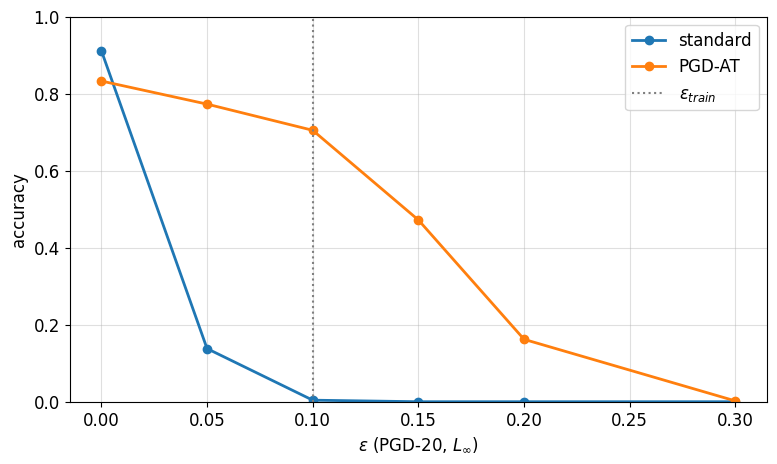

In [340]:
plt.figure(figsize=(9, 5))
for name, accs in robust_curves.items():
    plt.plot(eps_grid, accs, 'o-', linewidth=2, label=name)
plt.axvline(EPS_TRAIN, color='gray', linestyle=':', label=r'$\varepsilon_{train}$')
plt.xlabel(r'$\varepsilon$ (PGD-20, $L_\infty$)')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Сколько стоит робастность в clean accuracy? Что происходит при $\varepsilon > \varepsilon_{\text{train}}$? Во сколько раз PGD-AT дороже обычного обучения по числу forward/backward?

**Ответ.** Робастность стоит около 8 п.п. clean accuracy: 0.912 у обычной модели против 0.834 у PGD-AT. Взамен PGD-20 accuracy при $\varepsilon = 0.1$ выросла с 0.004 до 0.715 (FGSM — 0.741). Обучение при этом не сошлось: за 5 эпох PGD accuracy росла каждую эпоху (0.647 → 0.713), clean тоже (0.802 → 0.834). С большим бюджетом обе, скорее всего, подросли бы.

При $\varepsilon > \varepsilon_{\text{train}}$ robust accuracy быстро падает: 0.715 при 0.1, 0.453 при 0.15, 0.128 при 0.2 и 0.001 при 0.3 — то есть столько же, сколько у обычной модели. Модель учили отбиваться только от возмущений в шаре радиуса 0.1, и за его пределами защиты почти нет. Robustness не переносится на большие радиусы «бесплатно». Для сравнения, обычная модель ломается уже при $\varepsilon = 0.05$ (0.141).

По числу проходов: на каждом батче PGD-7 делает 7 forward + backward по входу, плюс ещё один forward + backward для шага по весам. Это 8 проходов вместо одного, то есть в 8 раз дороже. По времени (`RUN_TIMES`) вышло 39.2 с на PGD-AT против 5.7 с на обычное обучение, в 6.8 раза. Меньше восьми, потому что при построении атаки не считаются градиенты по параметрам. Зато в эти 39 с входит ещё и оценка FGSM/PGD-20 после каждой эпохи.

## 6.2 Диагностика оценки robustness (1 балл)

Реализуйте `sanity_checks(model, x, y, eps)` и верните четыре accuracy:

- `fgsm` — после FGSM;
- `pgd20` — после PGD-20 с random start;
- `pgd100_x5` — PGD-100 с пятью random restarts: объект считается сломанным, если он ошибочно классифицирован хотя бы в одном restart **или уже на clean**;
- `eps_1` — после PGD-20 с $\varepsilon=1$.

Для каждого поля clean-ошибки тоже считаются ошибками: атака не должна «исправлять» robust accuracy. Атакуйте батчами не более 128. В `FAST_MODE` сокращается только число объектов, число шагов и restarts остаётся тем же.

Обычно усиление атаки уменьшает accuracy; обратный результат — повод проверить step size, random start и loss. Независимые конечные PGD-прогоны не дают гарантированного порядка результатов. Низкая accuracy при большом радиусе — полезная диагностика, но прохождение всех sanity checks не доказывает отсутствие gradient masking и не сертифицирует robustness. См. [Athalye et al., 2018](https://arxiv.org/abs/1802.00420).

Эксперимент проводится на фиксированных первых 128 объектах в FAST_MODE и 256 в финальном режиме. Это диагностика, а не точная оценка accuracy всего датасета.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [341]:
SANITY_BATCH_SIZE = 128
PGD_RESTARTS = 5


def survives_attack(model, x, y, attack):
    with torch.no_grad():
        is_clean_correct = model(x).argmax(dim=1) == y
        is_adv_correct = model(attack(x, y)).argmax(dim=1) == y
    return is_clean_correct & is_adv_correct


def survives_restarts(model, x, y, attack, restarts):
    is_robust = survives_attack(model, x, y, attack)
    for _ in range(restarts - 1):
        is_robust &= survives_attack(model, x, y, attack)
    return is_robust


def sanity_checks(model, x, y, eps):
    model.eval()
    attacks = {
        'fgsm': lambda xb, yb: fgsm_attack(model, xb, yb, eps),
        'pgd20': lambda xb, yb: pgd(model, xb, yb, eps),
        'pgd100_x5': lambda xb, yb: pgd_attack(model, xb, yb, eps, alpha=2.5 * eps / 100, steps=100),
        'eps_1': lambda xb, yb: pgd(model, xb, yb, 1.0),
    }
    restarts = {'pgd100_x5': PGD_RESTARTS}
    results = {}
    for name, attack in attacks.items():
        n_robust = 0
        for i in range(0, len(x), SANITY_BATCH_SIZE):
            xb, yb = x[i:i + SANITY_BATCH_SIZE], y[i:i + SANITY_BATCH_SIZE]
            n_robust += survives_restarts(model, xb, yb, attack, restarts.get(name, 1)).sum().item()
        results[name] = n_robust / len(x)
    return results

In [342]:
torch.manual_seed(0)
N_SANITY = 128 if FAST_MODE else 256
checks = {name: sanity_checks(m, XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_TRAIN)
          for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
print(f'{"model":<22}' + ''.join(f'{k:>11}' for k in next(iter(checks.values()))))
for name, res in checks.items():
    assert set(res) == {'fgsm', 'pgd20', 'pgd100_x5', 'eps_1'}
    assert all(math.isfinite(v) and 0 <= v <= 1 for v in res.values())
    print(f'{name:<22}' + ''.join(f'{v:>11.3f}' for v in res.values()))

model                        fgsm      pgd20  pgd100_x5      eps_1
standard                    0.094      0.008      0.000      0.000
PGD-AT                      0.758      0.730      0.730      0.000


**Вопрос.** Насколько меняется оценка accuracy при усилении атаки? Есть ли подозрительные результаты и что вы проверили бы дополнительно? Может ли модель с высокой FGSM accuracy и почти нулевой PGD accuracy пройти все перечисленные sanity checks — и что тогда можно сказать о её robustness?

**Ответ.** На PGD-AT модели (256 объектов) оценка при усилении атаки почти не меняется: FGSM 0.766, PGD-20 0.742, PGD-100 с пятью рестартами тоже 0.742. Переход от FGSM к PGD снимает 2.4 п.п. — это 6 объектов. А впятеро больше шагов и пять рестартов не ломают ни одного объекта сверх PGD-20. У обычной модели похоже: FGSM 0.090, PGD-20 и PGD-100×5 по 0.008. При $\varepsilon = 1$ обе модели дают 0: картинку можно заменить чем угодно, и атака это находит. Значит, градиенты не «сломаны» полностью, и атака работает, когда ей позволено.

Подозрительно, пожалуй, только точное совпадение PGD-20 и PGD-100×5. Это может значить, что PGD-20 уже насыщен на этой маленькой модели. Но может значить и то, что все запуски застревают в одних и тех же местах, где градиент cross-entropy не помогает. Дополнительно я бы проверил: атаку с другим loss (margin-loss в духе CW, $z_{\text{max}, \ne y} - z_y$), кривую loss по шагам PGD (должна расти и выходить на плато), transfer-атаку с обычной модели и атаку без градиентов (например, Square Attack). Если какая-то из них заметно ниже 0.742, значит, оценка была завышена. Маленький зазор между FGSM и PGD — скорее хороший знак: при gradient masking FGSM обычно выглядит намного сильнее, чем PGD.

Модель с высокой FGSM accuracy и почти нулевой PGD accuracy эти проверки вполне пройдёт. Более сильная атака даёт меньшую accuracy — как и должно быть. При $\varepsilon = 1$ будет 0. PGD-100×5 будет не выше PGD-20. Но её robustness — это то, что показывает самая сильная атака, то есть почти ноль. Высокая FGSM accuracy тогда ничего не говорит о защите, это просто признак того, что одношаговая линеаризация на этой модели плохо работает (gradient masking). Ровно такая модель получилась в бонусе 7.5 после FGSM-обучения: FGSM accuracy во время обучения 0.97, PGD 0, и все четыре проверки она проходит. Sanity checks ловят только грубые ошибки оценки, а пройти их — необходимое, но не достаточное условие.

## 6.3 Градиент по входу у обычной и робастной модели (1 балл)

Карта $|\nabla_x z_y(x)|$ — saliency по логиту верного класса: $z_c(x)$ обозначает логит класса $c$, $y$ — верную метку. Это **другая величина**, чем градиент cross-entropy в FGSM. Если $p_c(x)=\mathrm{softmax}(z(x))_c$, то
$$
\nabla_x L_{\mathrm{CE}}(x,y)=\sum_c p_c(x)\nabla_x z_c(x)-\nabla_x z_y(x).
$$
Для некоторых adversarially trained моделей наблюдали более интерпретируемые input gradients ([Tsipras et al., 2019](https://arxiv.org/pdf/1805.12152)). Здесь проверяется, наблюдается ли такой эффект в нашем протоколе; вид saliency сам по себе не доказывает robustness.

1. Реализуйте `input_gradient(model, x, y)`, возвращающую $|\nabla_x z_y|$ для батча (без изменения `.grad` параметров).
2. Для стандартной модели и PGD-AT посчитайте долю массы градиента на фоне (пиксели с $x = 0$), среднюю по `XF_test[:1000]`, и нарисуйте карты для 8 картинок.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [343]:
def single_input_gradient(model, x, y):
    x = x.detach().requires_grad_(True)
    with torch.enable_grad():
        true_logit = model(x)[0, y[0]]
        grad, = torch.autograd.grad(true_logit, x)
    return grad.abs()


def input_gradient(model, x, y):
    # Считаем по одной картинке, а не батчем. На однородном фоне в окнах MaxPool стоят точные ничьи,
    # и в float32 cuDNN для разных размеров батча разбивает их по-разному: градиент уходит в другой
    # пиксель (до ~10% от максимума карты; во float64 батч и одиночный проход совпадают до 1e-16).
    # Поштучный проход даёт тот же результат, что ручной градиент для одной картинки.
    model.eval()
    return torch.cat([single_input_gradient(model, x[i:i + 1], y[i:i + 1]) for i in range(len(x))])


def background_share(s, x):
    return ((s * (x == 0)).flatten(1).sum(1) / s.flatten(1).sum(1).clamp_min(1e-12)).mean().item()

In [344]:
x, y = XF_test[:1000], YF_test[:1000]
g = input_gradient(model_a, x, y)
assert g.shape == x.shape and (g >= 0).all()
assert_no_param_grads(model_a)
x1 = x[:1].clone().requires_grad_(True)
manual, = torch.autograd.grad(model_a(x1)[0, y[0]], x1)
assert torch.allclose(g[:1], manual.abs())

grad_models = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
shares = {name: background_share(input_gradient(m, x, y), x) for name, m in grad_models.items()}
print(f'background pixels: {(x == 0).float().mean():.3f}')
shares

background pixels: 0.498


{'standard': 0.5745126008987427, 'PGD-AT': 0.23477999866008759}

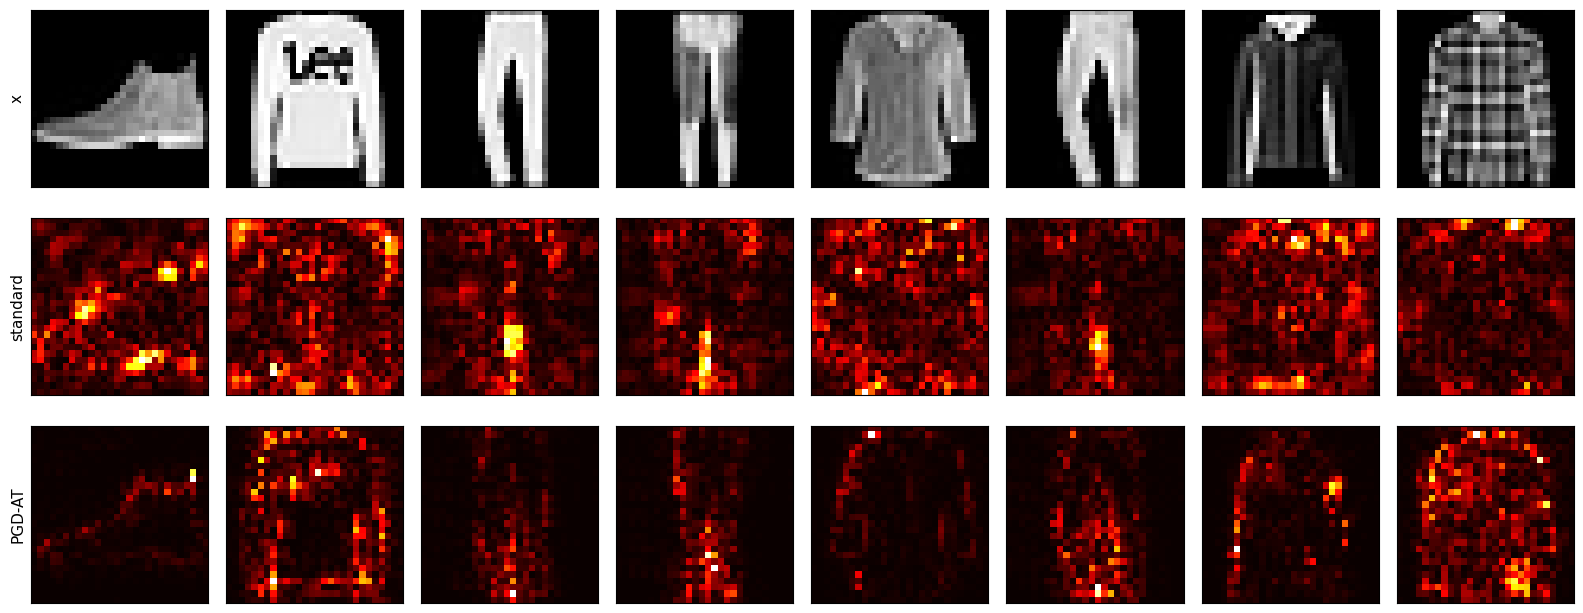

In [345]:
x8, y8 = XF_test[:8], YF_test[:8]
rows = {'x': x8} | {name: input_gradient(m, x8, y8) for name, m in grad_models.items()}
fig, axes = plt.subplots(len(rows), 8, figsize=(16, 2.2 * len(rows)))
for row, (label, images) in enumerate(rows.items()):
    for i in range(8):
        axes[row, i].imshow(images[i, 0].cpu(), cmap='gray' if row == 0 else 'hot')
        axes[row, i].set_xticks([])
        axes[row, i].set_yticks([])
    axes[row, 0].set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()

**Вопрос.** Чем отличаются карты моделей — визуально и по доле массы на фоне? Согласуется ли наблюдение с различием PGD accuracy в вашем эксперименте? Почему одной красивой saliency-карты недостаточно для вывода о robustness?

**Ответ.** Визуально карты сильно отличаются. У обычной модели градиент шумный и размазан по всему кадру, включая фон. Самые яркие пятна часто стоят прямо на фоне: у всех трёх брюк это зазор между штанинами, у ботинка — пустое место над ним. У PGD-AT фон почти чёрный, а масса сидит на самом предмете: контур ботинка, края и низ свитера, клетка на рубашке. Карты всё ещё пиксельно-зернистые, «красивых» гладких картинок, как у Tsipras et al., не получилось. Но силуэт угадывается. По числам: фоновые пиксели — 49.8% картинки. У обычной модели на них приходится 57.6% массы градиента, то есть даже больше, чем на их долю по площади. У PGD-AT — 21.9%, в 2.6 раза меньше. Цветовая шкала у каждой карты своя, так что яркость между моделями напрямую не сравнить, только форму.

С разницей в PGD accuracy (0.004 против 0.715 при $\varepsilon = 0.1$) это согласуется. Обычная модель чувствительна к фону, где сдвиг на 0.1 вообще не меняет, что изображено. Атаке есть куда ударить дёшево, и FGSM/PGD ровно туда и бьют (то же видно на картах возмущений в 5.1). Робастная модель на фон почти не реагирует, и атаке приходится менять сам предмет. Но это корреляция на двух моделях, а не доказательство причины.

Почему одной красивой карты мало. Saliency — это градиент в одной точке, линейное приближение. А robustness — про худший случай во всём $\varepsilon$-шаре. Модель с gradient masking может давать аккуратный или почти нулевой градиент в точке и при этом ломаться от атаки, которая обходит это место (вспомним 6.2 и 7.5: FGSM может быть высоким при нулевом PGD). К тому же это 8 картинок из 1000, и их вид зависит от нормировки цветовой шкалы. Вывод о robustness можно делать только по сильным атакам, а карта — лишь иллюстрация того, на что модель смотрит.

### Сохранение результатов обязательной части

Ячейка сохраняет `metrics.json` и три checkpoint в `artifacts/`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode=false`. Сдайте их вместе с ноутбуком. NaN в матрице targeted success записываются как JSON `null`. Checkpoints содержат только `state_dict`, без сериализации объекта модели.

In [346]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    schema_version=2, fast_mode=FAST_MODE, attack_track=ATTACK_TRACK,
    environment=dict(torch=torch.__version__, device=str(device)),
    data=dict(cifar_train=len(X_train), cifar_test=len(X_test),
              fashion_train=len(XF_train), fashion_test=len(XF_test)),
    config=dict(seed=0, cifar_epochs=EPOCHS, ablation_epochs=ABL_EPOCHS,
                cifar_lr=LR, cifar_mean=CIFAR_MEAN, cifar_std=CIFAR_STD,
                fashion_epochs=FM_EPOCHS, at_epochs=AT_EPOCHS, eps_train=EPS_TRAIN),
    cifar=dict(history=history_cifar, ablations=ablation),
    attacks=dict(l2_eps=eps_l2, l2_accuracy=acc_l2, linf_accuracy=acc_linf,
                 selected=S if ATTACK_TRACK == 'targeted' else transfer),
    adversarial=dict(history=at_history, eps=eps_grid, accuracy=robust_curves,
                     sanity=checks, background_share=shares),
    timings=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2,
                                                    allow_nan=False), encoding='utf-8')
for name, model in [('resnet20', resnet20), ('fashion_standard', model_a), ('fashion_pgd_at', robust['PGD-7'])]:
    torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, artifact_dir / f'{name}.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['fashion_pgd_at.pt', 'fashion_standard.pt', 'metrics.json', 'resnet20.pt']


---
# 7\*. Бонусные задачи

## 7.1 Edge of stability (1.5 балла)

Для положительно определённой квадратичной функции GD сходится при $0 < \eta < 2/\lambda_{\max}$, где $\lambda_{\max}$ — наибольшее собственное число гессиана. [Gradient Descent on Neural Networks Typically Occurs at the Edge of Stability](https://arxiv.org/pdf/2103.00065), Cohen et al., 2021: у нейросети sharpness $\lambda_{\max}(\nabla^2 L)$ во время full-batch GD растёт (progressive sharpening), пока не дойдёт до $2/\eta$, и дальше держится около этой границы — loss при этом немонотонный, но продолжает убывать.

1. Реализуйте `hvp(grads, params, v)`: градиент считается один раз с `create_graph=True`, а $Hv$ — VJP градиента с вектором $v$ (`grad_outputs` в `torch.autograd.grad`); гессиан $H$ явно не строится.
2. `top_eigenvalue` ниже — готовый Lanczos с reorthogonalization. Он оценивает **наибольшее algebraic eigenvalue** через наибольшее eigenvalue небольшой tridiagonal matrix. Обычная power iteration для indefinite Hessian может найти отрицательное eigenvalue с наибольшим модулем и здесь не подходит. Менять готовый solver не требуется; проверьте HVP и solver на тестах, включая indefinite quadratic.
3. Full-batch GD (`SGD` без momentum) для MLP с двумя скрытыми слоями по 200 нейронов и tanh на первых 2000 картинках FashionMNIST, loss — MSE по one-hot $\frac12 \|f(x) - e_y\|^2$ (среднее по объектам). Для нескольких $\eta$ записывать loss на каждом шаге и $\lambda_{\max}$ каждые 50 шагов. График: $\lambda_{\max}$ по шагам с горизонталями $2/\eta$.

**Оценивание:** код — 0.7; эксперимент — 0.4; объяснение — 0.4 балла.

In [347]:
if '7.1' in BONUS_TASKS:
    def hvp(grads, params, v):
        # grads = torch.autograd.grad(loss, params, create_graph=True); v — список тензоров формы params
        return torch.autograd.grad(grads, params, grad_outputs=v, retain_graph=True)


    def top_eigenvalue(loss_fn, params, iters=20, v=None):
        # Готовый solver: largest algebraic Ritz value, не eigenvalue наибольшего модуля.
        params = list(params)
        sizes = [p.numel() for p in params]
        total = sum(sizes)
        if iters < 1:
            raise ValueError('iters must be positive')
        def unpack(flat):
            return [part.view_as(p) for part, p in zip(flat.split(sizes), params)]
        q = torch.randn(total, device=params[0].device, dtype=params[0].dtype)
        if v is not None:
            # Небольшой шум не даёт warm start застрять в одном инвариантном подпространстве.
            q = torch.cat([vi.detach().flatten() for vi in v]) + 1e-3 * q / q.norm()
        q = q / q.norm()
        grads = torch.autograd.grad(loss_fn(), params, create_graph=True)
        basis, diagonal, off_diagonal = [], [], []
        for k in range(min(iters, total)):
            basis.append(q)
            z = torch.cat([h.detach().flatten() for h in hvp(grads, params, unpack(q))])
            if k:
                z = z - off_diagonal[-1] * basis[-2]
            alpha = torch.dot(q, z)
            diagonal.append(alpha)
            z = z - alpha * q
            Q = torch.stack(basis)
            for _ in range(2):
                z = z - (Q @ z) @ Q
            beta = z.norm()
            if beta.item() < 1e-7 or k + 1 == min(iters, total):
                break
            off_diagonal.append(beta)
            q = z / beta
        T = torch.diag(torch.stack(diagonal))
        if off_diagonal:
            off = torch.stack(off_diagonal)
            T += torch.diag(off, diagonal=1) + torch.diag(off, diagonal=-1)
        # Маленькая eigenproblem на CPU, в том числе при основном обучении на MPS.
        values, vectors = torch.linalg.eigh(T.cpu().double())
        coeffs = vectors[:, -1].to(device=q.device, dtype=q.dtype)
        eigenvector = coeffs @ torch.stack(basis)
        return values[-1].item(), unpack(eigenvector)

In [348]:
if '7.1' in BONUS_TASKS:
    torch.manual_seed(0)
    Q = torch.linalg.qr(torch.randn(30, 30))[0]
    A = Q @ torch.diag(torch.linspace(0.1, 7, 30)) @ Q.T
    w = torch.randn(30, requires_grad=True)
    grads = torch.autograd.grad(0.5 * w @ A @ w, [w], create_graph=True)
    v = torch.randn(30)
    assert torch.allclose(hvp(grads, [w], [v])[0], A @ v, atol=1e-5)

    p = torch.tensor([1.0, -2.0], requires_grad=True)
    lam, _ = top_eigenvalue(lambda: 0.5 * (p[0] ** 2 + 20 * p[1] ** 2), [p], iters=50)
    assert abs(lam - 20) < 1e-3
    lam, _ = top_eigenvalue(lambda: 0.5 * w @ A @ w, [w], iters=300)
    assert abs(lam - 7) < 1e-2
    lam, _ = top_eigenvalue(lambda: 0.5 * (-10 * p[0] ** 2 + 2 * p[1] ** 2), [p], iters=10)
    assert abs(lam - 2) < 1e-4, lam

In [349]:
if '7.1' in BONUS_TASKS:
    N_EOS = 256 if FAST_MODE else 2000
    EOS_STEPS = 100 if FAST_MODE else 3000
    X_eos = XF_train[:N_EOS].flatten(1)
    X_eos = X_eos - X_eos.mean(dim=0)
    Y_eos = F.one_hot(YF_train[:N_EOS], 10).float()


    def make_tanh_mlp(seed=0):
        torch.manual_seed(seed)
        return nn.Sequential(nn.Linear(784, 200), nn.Tanh(), nn.Linear(200, 200), nn.Tanh(), nn.Linear(200, 10)).to(device)


    def mse_loss(model):
        return 0.5 * ((model(X_eos) - Y_eos) ** 2).sum(dim=1).mean()

In [350]:
if '7.1' in BONUS_TASKS:
    EOS_LRS = [0.02, 0.04, 0.08, 0.16]
    SHARPNESS_EVERY = 50
    LANCZOS_ITERS = 20


    def run_full_batch_gd(lr, steps=EOS_STEPS, seed=0):
        model = make_tanh_mlp(seed)
        params = list(model.parameters())
        optimizer = torch.optim.SGD(params, lr=lr)
        run = dict(loss=[], sharpness_steps=[], sharpness=[])
        top_vector = None
        for step in range(steps):
            loss = mse_loss(model)
            if not math.isfinite(loss.item()):
                print(f'lr={lr}: loss разошёлся на шаге {step}')
                break
            run['loss'].append(loss.item())
            if step % SHARPNESS_EVERY == 0:
                sharpness, top_vector = top_eigenvalue(lambda: mse_loss(model), params, LANCZOS_ITERS, top_vector)
                run['sharpness_steps'].append(step)
                run['sharpness'].append(sharpness)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        model.zero_grad(set_to_none=True)
        return run


    started = time.perf_counter()
    eos_runs = {lr: run_full_batch_gd(lr) for lr in EOS_LRS}
    RUN_TIMES['eos_seconds'] = time.perf_counter() - started
    for lr, run in eos_runs.items():
        sharp = np.array(run['sharpness'])
        print(f'lr={lr:<5} 2/lr={2 / lr:>6.1f}  sharpness: start {sharp[0]:6.1f}  max {sharp.max():6.1f}  '
              f'last {sharp[-1]:6.1f}   loss: start {run["loss"][0]:.4f}  last {run["loss"][-1]:.4f}  '
              f'steps with loss increase: {int((np.diff(run["loss"]) > 0).sum())}')

lr=0.02  2/lr= 100.0  sharpness: start    4.4  max   16.9  last   16.9   loss: start 0.4973  last 0.1494  steps with loss increase: 0
lr=0.04  2/lr=  50.0  sharpness: start    4.4  max   33.6  last   33.6   loss: start 0.4973  last 0.1217  steps with loss increase: 0
lr=0.08  2/lr=  25.0  sharpness: start    4.4  max   28.0  last   26.0   loss: start 0.4973  last 0.0943  steps with loss increase: 803
lr=0.16  2/lr=  12.5  sharpness: start    4.4  max   14.2  last   13.3   loss: start 0.4973  last 0.0775  steps with loss increase: 1298


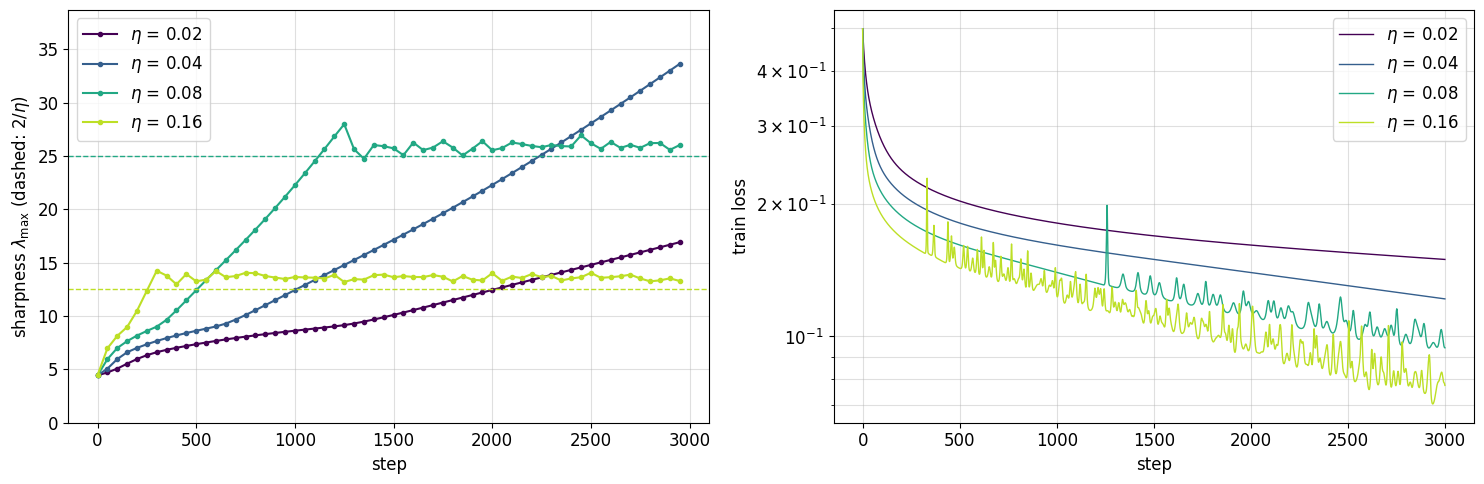

In [351]:
if '7.1' in BONUS_TASKS:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    for (lr, run), color in zip(eos_runs.items(), plt.cm.viridis(np.linspace(0, 0.9, len(eos_runs)))):
        ax1.plot(run['sharpness_steps'], run['sharpness'], 'o-', color=color, markersize=3, label=rf'$\eta$ = {lr}')
        ax1.axhline(2 / lr, color=color, linestyle='--', linewidth=1)
        ax2.semilogy(run['loss'], color=color, linewidth=1, label=rf'$\eta$ = {lr}')
    ax1.set_ylim(0, 1.15 * max(max(r['sharpness']) for r in eos_runs.values()))
    ax1.set_ylabel(r'sharpness $\lambda_{\max}$ (dashed: $2/\eta$)')
    ax2.set_ylabel('train loss')
    for ax in (ax1, ax2):
        ax.set_xlabel('step')
        ax.grid(True, which='both', alpha=0.4)
        ax.legend()
    plt.tight_layout()
    plt.show()

**Вопрос.** В каких прогонах sharpness приблизилась к $2/\eta$? Если выхода на границу не было, укажите это. Сопоставьте изменения sharpness и loss. Почему локальный критерий для фиксированной положительно определённой квадратичной функции не гарантирует такую же динамику нелинейной сети?

**Ответ.** На границу $2/\eta$ вышли два прогона из четырёх. При $\eta = 0.08$ sharpness росла почти линейно от 4.4 до 28 к шагу ~1250, чуть перескочила границу 25, а дальше до конца (ещё ~1750 шагов) держалась на 25–27. При $\eta = 0.16$ то же самое, только быстрее: к шагу ~300 дошла до 14.2 при границе 12.5 и дальше стояла на 13–14. При $\eta = 0.02$ и $0.04$ progressive sharpening тоже есть: sharpness выросла до 16.9 и 33.6. Но до границы (100 и 50) за 3000 шагов она не дошла, к концу просто продолжала расти.

Loss ведёт себя ровно как в статье. Пока sharpness ниже $2/\eta$, он убывает монотонно: при $\eta = 0.02$ и $0.04$ — ни одного шага с ростом loss. Как только sharpness упирается в границу, loss становится немонотонным: 803 шага из 3000 с ростом при $\eta = 0.08$ и 1298 при $\eta = 0.16$. Самые заметные всплески совпадают с моментом выхода на границу: при $\eta = 0.08$ резкий скачок loss на шаге ~1250, ровно когда sharpness дошла до 28, после чего она откатилась к 24.7. При $\eta = 0.16$ такой же всплеск около шага 330. Но в среднем loss продолжает падать, и итог у этих прогонов даже ниже (0.094 и 0.078 против 0.149 и 0.122), просто потому что шаг больше. Оговорка: sharpness меряем раз в 50 шагов, так что мелкие колебания вокруг границы мы не видим.

Почему квадратичный критерий не переносится на сеть. Для квадратичной функции гессиан постоянный: если $\lambda_{\max} > 2/\eta$, колебания вдоль верхнего собственного направления растут экспоненциально, и GD расходится. У сети гессиан зависит от точки и меняется вместе с траекторией. Сначала GD сам заходит в более острую область (progressive sharpening). Когда шаг становится неустойчивым, колебания выбрасывают параметры туда, где кривизна меньше — это эффект членов выше второго порядка, которых в квадратичной модели нет. Поэтому sharpness «самостабилизируется» у $2/\eta$ вместо расходимости, а условие $\eta < 2/\lambda_{\max}$ — это локальное условие монотонного спуска, а не условие сходимости для нелинейной сети.

## 7.2 Свёртка через FFT со stride, padding и groups (0.5 балла)

Теорема о свёртке: $\mathcal F(x * w) = \mathcal F(x) \cdot \mathcal F(w)$. Детали:

- DFT считает циклическую свёртку — дополняем нулями до $H + k_h - 1$ по высоте и $W + k_w - 1$ по ширине;
- `F.conv2d` — cross-correlation, поэтому ядро переворачивается;
- сумма по входным каналам остаётся суммой в частотной области; с `groups` — только внутри группы;
- padding — `F.pad` входа; stride $s$ — прореживание «valid»-результата $[\,::s,\; ::s\,]$.

Реализуйте `conv2d_fft` (dilation = 1; stride и padding — целые числа) через `torch.fft.rfft2` / `irfft2` и `einsum`.

**Оценивание:** код — 0.4; эксперимент — 0; объяснение — 0.1 балла.

In [352]:
if '7.2' in BONUS_TASKS:
    def conv2d_fft(x, weight, bias=None, stride=1, padding=0, groups=1):
        x = F.pad(x, (padding, padding, padding, padding))
        B, C_in, H, W = x.shape
        C_out, _, kh, kw = weight.shape
        fft_size = (H + kh - 1, W + kw - 1)

        x_freq = torch.fft.rfft2(x, s=fft_size)
        w_freq = torch.fft.rfft2(weight.flip(-2, -1), s=fft_size)

        x_freq = x_freq.view(B, groups, C_in // groups, *x_freq.shape[-2:])
        w_freq = w_freq.view(groups, C_out // groups, C_in // groups, *w_freq.shape[-2:])
        out_freq = torch.einsum('bgchw,gochw->bgohw', x_freq, w_freq).reshape(B, C_out, *x_freq.shape[-2:])
        full = torch.fft.irfft2(out_freq, s=fft_size)

        out = full[:, :, kh - 1:H, kw - 1:W][:, :, ::stride, ::stride]
        if bias is not None:
            out = out + bias.view(1, -1, 1, 1)
        return out

In [353]:
if '7.2' in BONUS_TASKS:
    torch.manual_seed(0)
    x = torch.randn(2, 4, 13, 10)
    n_checked = 0
    for k, s, p, g in itertools.product([1, 3, (3, 5)], [1, 2, 3], [0, 1, 2], [1, 2, 4]):
        w, b = torch.randn(8, 4 // g, *pair(k)), torch.randn(8)
        ref = F.conv2d(x, w, b, stride=s, padding=p, groups=g)
        out = conv2d_fft(x, w, b, stride=s, padding=p, groups=g)
        assert out.shape == ref.shape and torch.allclose(out, ref, atol=1e-4), (k, s, p, g)
        n_checked += 1
    n_checked

**Вопрос.** Какую долю посчитанных выходов FFT-свёртка выбрасывает при stride $s$? Когда FFT-свёртка всё равно выгоднее прямой?

**Ответ.** FFT считает свёртку целиком: на сетке $(H + k_h - 1) \times (W + k_w - 1)$ получается вся «полная» свёртка, из неё берём valid-часть, а из valid-части при stride $s$ только каждую $s$-ю строку и столбец. От valid-выходов остаётся доля $1/s^2$, выбрасывается $1 - 1/s^2$: 75% при $s = 2$, 89% при $s = 3$. Плюс сверху ещё выбрасываются края полной свёртки. Прямой свёртке со stride просто не нужно считать эти позиции, а FFT по своей природе даёт все сразу.

FFT всё равно выгоднее при больших ядрах и stride 1. У прямой свёртки и im2col стоимость растёт как $k^2$ (см. 1.1), а у FFT от размера ядра почти не зависит: $O(HW \log HW)$ на преобразование. Ещё помогает много каналов: FFT каждого входного канала считается один раз и переиспользуется для всех выходных каналов, а FFT ядер на инференсе можно посчитать заранее. Для типичных $3 \times 3$ со stride 2 FFT проигрывает: и выбрасывает большую часть работы, и на маленьком ядре не получает своего преимущества.

## 7.3 Muon для свёрточных весов (1 балл)

[Muon: An optimizer for hidden layers in neural networks](https://kellerjordan.github.io/posts/muon/), Jordan et al., 2024. Для матричного параметра $W \in \mathbb R^{m \times n}$ с градиентом $G_t$ — так он устроен в `torch.optim.Muon` (momentum через EMA, Nesterov):
$$
B_t = \mu B_{t-1} + (1 - \mu)\, G_t, \qquad U_t = (1 - \mu)\, G_t + \mu B_t, \qquad
W \leftarrow W - \eta \sqrt{\max(1,\, m/n)}\; \mathrm{NS}_5(U_t),
$$
где $\mathrm{NS}_5$ — 5 итераций Ньютона–Шульца, приближающие ортогональный множитель $P Q^\top$ из SVD $U_t = P \Sigma Q^\top$:
$$
X_0 = \frac{U_t}{\|U_t\|_F}, \qquad X_{j+1} = a X_j + b\, (X_j X_j^\top) X_j + c\, (X_j X_j^\top)^2 X_j, \qquad (a, b, c) = (3.4445,\, -4.7750,\, 2.0315)
$$
(если $m > n$, итерации идут для $X^\top$). `torch.optim.Muon` принимает только 2D-параметры, а вес свёртки $(C_{\text{out}}, C_{\text{in}}, k, k)$ — это матрица $C_{\text{out}} \times C_{\text{in}} k^2$ (та же, что в `conv2d_unfold`).

1. Реализуйте `newton_schulz` и `ConvMuon` (без weight decay) для параметров любой размерности $\ge 2$: первая ось — строки, остальные разворачиваются в столбцы. Библиотечный Muon считает итерации в bfloat16, поэтому сравнение с ним — с допуском.
2. Обучите ResNet-20: `ConvMuon` с `MUON_LR` для всех 4D-весов, `MyAdamW` как в `train_cifar` для остального (BN, голова), у обоих cosine schedule, бюджет `EPOCHS`, тот же `set_seed(0)`. Сравните с `history_cifar` из 4.2. Здесь сравниваются два фиксированных training recipe, включая разный weight decay на conv-весах; этот опыт не изолирует влияние одного лишь optimizer и не является общим рейтингом.

**Оценивание:** код — 0.5; эксперимент — 0.3; объяснение — 0.2 балла.

In [354]:
if '7.3' in BONUS_TASKS:
    NS_EPS = 1e-7


    def newton_schulz(M, steps=5, coeffs=(3.4445, -4.7750, 2.0315)):
        a, b, c = coeffs
        is_tall = M.shape[0] > M.shape[1]
        X = M.T if is_tall else M
        X = X / (X.norm() + NS_EPS)
        for _ in range(steps):
            gram = X @ X.T
            X = a * X + (b * gram + c * gram @ gram) @ X
        return X.T if is_tall else X


    class ConvMuon(torch.optim.Optimizer):
        def __init__(self, params, lr=0.02, momentum=0.95):
            super().__init__(params, dict(lr=lr, momentum=momentum))

        @torch.no_grad()
        def step(self):
            for group in self.param_groups:
                mu = group['momentum']
                for p in group['params']:
                    if p.grad is None:
                        continue
                    state = self.state[p]
                    if not state:
                        state['momentum_buffer'] = torch.zeros_like(p)
                    buffer = state['momentum_buffer']
                    buffer.lerp_(p.grad, 1 - mu)
                    nesterov_update = p.grad.lerp(buffer, mu)

                    matrix = nesterov_update.reshape(p.shape[0], -1)
                    rows, cols = matrix.shape
                    scale = math.sqrt(max(1.0, rows / cols))
                    p.add_(newton_schulz(matrix).view_as(p), alpha=-group['lr'] * scale)

In [355]:
if '7.3' in BONUS_TASKS:
    def muon_steps(make_optimizer, shape, steps=5):
        torch.manual_seed(0)
        p = torch.randn(shape, requires_grad=True)
        optimizer = make_optimizer(p)
        gen = torch.Generator().manual_seed(1)
        for _ in range(steps):
            optimizer.zero_grad()
            (p * torch.randn(shape, generator=gen)).sum().backward()
            optimizer.step()
        return p.detach()


    torch.manual_seed(0)
    M = torch.randn(64, 32) * torch.logspace(0, -3, 32)
    assert torch.linalg.svdvals(newton_schulz(M)).max() < 1.3

    for shape in [(48, 20), (20, 48)]:
        start = muon_steps(lambda p: torch.optim.SGD([p], lr=0.0), shape)   # lr = 0: начальная точка
        mine = muon_steps(lambda p: ConvMuon([p], lr=0.02), shape)
        ref = muon_steps(lambda p: torch.optim.Muon([p], lr=0.02, weight_decay=0.0), shape)
        assert ((mine - ref).norm() / (ref - start).norm()) < 0.05, shape

    conv_w = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 8, 3, 3))
    flat = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 72))
    assert torch.allclose(conv_w.view(16, 72), flat, atol=1e-6)

In [356]:
if '7.3' in BONUS_TASKS:
    MUON_LR = 0.02


    def train_cifar_muon(model, epochs, adam_lr, muon_lr, weight_decay=0.05, batch_size=256, log=True):
        model = model.to(device)
        conv_weights = [p for p in model.parameters() if p.ndim == 4]
        other_matrices = [p for p in model.parameters() if p.ndim in (2, 3)]
        vectors = [p for p in model.parameters() if p.ndim <= 1]
        optimizers = [ConvMuon(conv_weights, lr=muon_lr),
                      MyAdamW([dict(params=other_matrices, weight_decay=weight_decay),
                               dict(params=vectors, weight_decay=0.0)], lr=adam_lr)]
        total_steps = epochs * math.ceil(len(X_train) / batch_size)
        schedulers = [torch.optim.lr_scheduler.LambdaLR(opt, lambda step: cosine_lr(step, total_steps, 0.0))
                      for opt in optimizers]
        history = dict(train_loss=[], test_acc=[])
        start = time.time()
        for epoch in range(epochs):
            model.train()
            loss_sum = 0.0
            for xb, yb in iterate_batches(X_train, Y_train, batch_size, transform=normalize):
                loss = F.cross_entropy(model(xb), yb)
                for opt in optimizers:
                    opt.zero_grad()
                loss.backward()
                for opt, scheduler in zip(optimizers, schedulers):
                    opt.step()
                    scheduler.step()
                loss_sum += loss.item() * len(yb)
            history['train_loss'].append(loss_sum / len(X_train))
            history['test_acc'].append(accuracy(predict_logits(model, X_test, transform=normalize), Y_test))
            if log:
                print(f'epoch {epoch + 1:>3}/{epochs}  train loss {history["train_loss"][-1]:.4f}  '
                      f'test acc {history["test_acc"][-1]:.4f}  {time.time() - start:.0f}s')
        return history


    set_seed(0)
    resnet20_muon = ResNetCIFAR(20)
    started = time.perf_counter()
    hist_muon = train_cifar_muon(resnet20_muon, EPOCHS, LR, MUON_LR)
    RUN_TIMES['cifar_resnet20_muon_seconds'] = time.perf_counter() - started
    hist_adamw = history_cifar
    print(f'{"":<10}{"train loss":>12}{"test acc":>10}')
    for name, hist in [('AdamW', hist_adamw), ('Muon', hist_muon)]:
        print(f'{name:<10}{hist["train_loss"][-1]:>12.4f}{hist["test_acc"][-1]:>10.4f}')

epoch   1/20  train loss 1.1405  test acc 0.6231  15s
epoch   2/20  train loss 0.6744  test acc 0.7370  31s
epoch   3/20  train loss 0.5088  test acc 0.7877  46s
epoch   4/20  train loss 0.4020  test acc 0.8213  62s
epoch   5/20  train loss 0.3181  test acc 0.8157  77s
epoch   6/20  train loss 0.2427  test acc 0.8156  93s
epoch   7/20  train loss 0.1818  test acc 0.8152  109s
epoch   8/20  train loss 0.1271  test acc 0.8267  124s
epoch   9/20  train loss 0.0906  test acc 0.8334  139s
epoch  10/20  train loss 0.0604  test acc 0.8238  155s
epoch  11/20  train loss 0.0436  test acc 0.8257  170s
epoch  12/20  train loss 0.0279  test acc 0.8374  186s
epoch  13/20  train loss 0.0169  test acc 0.8399  201s
epoch  14/20  train loss 0.0098  test acc 0.8456  217s
epoch  15/20  train loss 0.0056  test acc 0.8443  232s
epoch  16/20  train loss 0.0032  test acc 0.8491  248s
epoch  17/20  train loss 0.0018  test acc 0.8475  263s
epoch  18/20  train loss 0.0010  test acc 0.8496  278s
epoch  19/20  tr

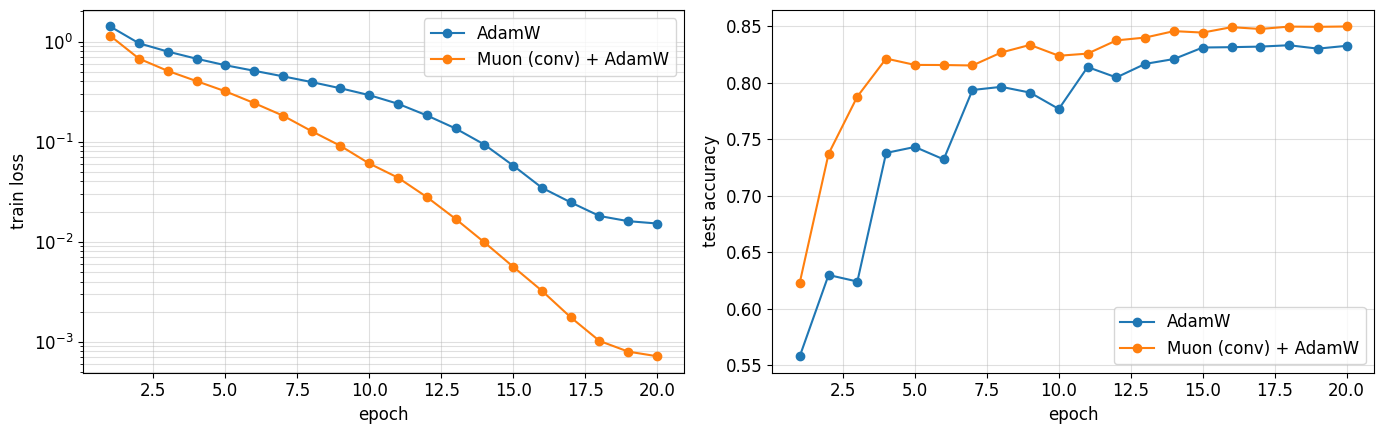

In [357]:
if '7.3' in BONUS_TASKS:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
    for name, hist in [('AdamW', hist_adamw), ('Muon (conv) + AdamW', hist_muon)]:
        epochs_axis = range(1, len(hist['test_acc']) + 1)
        ax1.semilogy(epochs_axis, hist['train_loss'], 'o-', label=name)
        ax2.plot(epochs_axis, hist['test_acc'], 'o-', label=name)
    ax1.set_ylabel('train loss')
    ax2.set_ylabel('test accuracy')
    for ax in (ax1, ax2):
        ax.set_xlabel('epoch')
        ax.grid(True, which='both', alpha=0.4)
        ax.legend()
    plt.tight_layout()
    plt.show()

**Вопрос.** Какой оптимизатор быстрее снижает train loss и какой даёт лучшую test accuracy при том же бюджете? Сколько памяти состояния на параметр у каждого?

**Ответ.** В моём прогоне Muon (на свёртках) + AdamW (на остальном) выиграл по обоим показателям. Train loss он снижает заметно быстрее: после 1-й эпохи 1.14 против 1.42 у чистого AdamW, после 5-й 0.32 против 0.58, в конце 0.0007 против 0.014 — в 20 раз ниже. Test accuracy тоже лучше: 85.6% против 82.8%, и впереди он с первой же эпохи (0.633 против 0.475). По времени эпоха с Muon чуть дороже: 300 с против 254 с за всё обучение, это цена пяти итераций Ньютона–Шульца на каждый шаг.

Оговорки, как и сказано в условии. Сравниваются два рецепта, а не два оптимизатора: у Muon на свёрточных весах нет weight decay, а AdamW штрафует их с коэффициентом 0.05. Learning rate ни для одного не подбирался. И это один seed. Так что вывод «Muon лучше» отсюда не следует, только «этот рецепт на этом бюджете дал лучше».

Память состояния: AdamW хранит два буфера на параметр — первый и второй моменты, то есть 2 числа на параметр (плюс счётчик шагов на тензор). Muon хранит один буфер momentum — 1 число на параметр. В нашей схеме почти все параметры ResNet-20 — свёрточные веса, так что состояние оптимизатора примерно вдвое меньше, чем у чистого AdamW.

## 7.4 $L_0$-атака на $L_\infty$-робастную модель (1 балл)

Ограничение — число изменённых пикселей:
$$
\max_{\|\delta\|_0 \le k,\;\; x + \delta \in [0, 1]^d} L\big(f(x + \delta), y\big).
$$
Линеаризация: пиксель $i$ выгоднее всего довести до 0 или до 1, прирост loss
$$
\mathrm{gain}_i = \max\big(g_i (1 - x_i),\; -g_i\, x_i\big), \qquad g = \nabla_x L.
$$
Жадная атака: $k$ раз пересчитать градиент и изменить ещё не тронутый пиксель с максимальным $\mathrm{gain}_i$ — на 1, если $g_i > 0$, иначе на 0.

1. Используйте готовую `greedy_pixel_attack` из семинара 4 ниже; переписывать её не требуется. Баллы — за эксперимент и интерпретацию.
2. Accuracy от $k$ для стандартной модели и PGD-AT на `XF_test[:500]`.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [358]:
if '7.4' in BONUS_TASKS:
    def greedy_pixel_attack(model, x, y, k):
        x_adv = x.detach().clone()
        changed = torch.zeros_like(x_adv, dtype=torch.bool)
        for _ in range(k):
            x_adv.requires_grad_(True)
            with torch.enable_grad():
                grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y, reduction='sum'), x_adv)
            x_adv = x_adv.detach()
            gain = torch.maximum(grad * (1 - x_adv), -grad * x_adv).masked_fill(changed, -float('inf'))
            idx = gain.flatten(1).argmax(dim=1, keepdim=True)
            new_val = (grad.flatten(1).gather(1, idx) > 0).float()
            x_adv = x_adv.flatten(1).scatter(1, idx, new_val).view_as(x)
            changed = changed.flatten(1).scatter(1, idx, True).view_as(x)
        return x_adv

In [359]:
if '7.4' in BONUS_TASKS:
    x, y = XF_test[:500], YF_test[:500]
    x5 = greedy_pixel_attack(model_a, x, y, k=5)
    n_changed = ((x5 - x).flatten(1) != 0).sum(dim=1)
    assert n_changed.max() <= 5 and x5.min() >= 0 and x5.max() <= 1
    assert torch.isin(x5[x5 != x], torch.tensor([0.0, 1.0], device=x.device)).all()
    assert_no_param_grads(model_a)
    print({'clean': attack_accuracy(model_a, x, y), 'L0, k=5': attack_accuracy(model_a, x5, y)})

    ks = [0, 1, 2, 3, 5, 10, 20, 30]
    l0_curves = {name: [attack_accuracy(m, greedy_pixel_attack(m, x, y, k), y) for k in ks]
                 for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
    for name, accs in l0_curves.items():
        print(f'{name:<10}' + ''.join(f'{a:>7.3f}' for a in accs))

{'clean': 0.916, 'L0, k=5': 0.634}
standard    0.916  0.898  0.840  0.760  0.634  0.404  0.178  0.062
PGD-AT      0.846  0.812  0.790  0.754  0.716  0.618  0.428  0.284


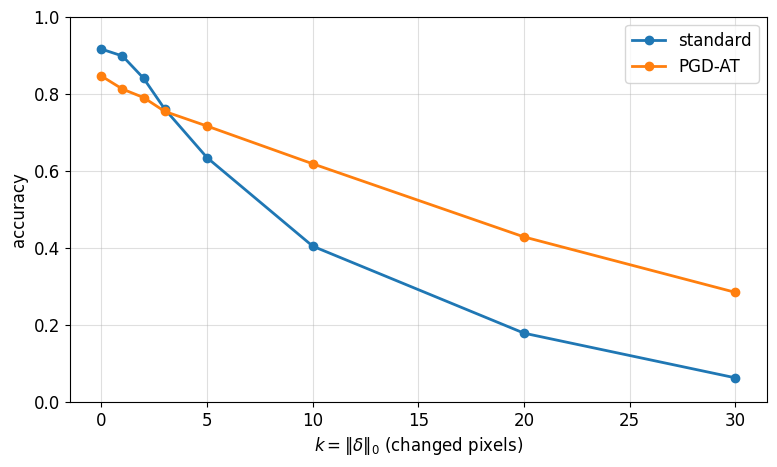

In [360]:
if '7.4' in BONUS_TASKS:
    plt.figure(figsize=(9, 5))
    for name, accs in l0_curves.items():
        plt.plot(ks, accs, 'o-', linewidth=2, label=name)
    plt.xlabel(r'$k = \|\delta\|_0$ (changed pixels)')
    plt.ylabel('accuracy')
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(True, alpha=0.4)
    plt.show()

**Вопрос.** Помогает ли робастность в $L_\infty$ против $L_0$-атаки? Почему $L_\infty$-шар радиуса $\varepsilon$ не защищает от изменения одного пикселя с 0 до 1?

**Ответ.** Помогает частично. При малом числе пикселей разницы почти нет: при $k = 3$ у обеих моделей 0.760, хотя PGD-AT стартует с меньшей clean accuracy (0.850 против 0.916). Дальше робастная модель деградирует медленнее: при $k = 10$ — 0.638 против 0.416, при $k = 30$ — 0.322 против 0.052. Но защитой это не назовёшь: 30 пикселей — это меньше 4% картинки, а PGD-AT теряет на них 53 п.п. Ещё и атака тут слабая (жадная, по одному пикселю за шаг, по линеаризации), так что реальная accuracy против $L_0$ может быть ещё ниже.

Почему $L_\infty$-шар не защищает. Сдвиг одного пикселя с 0 до 1 — это возмущение с $L_\infty$-нормой 1, в 10 раз больше $\varepsilon = 0.1$. Такие примеры лежат далеко за пределами шара, на котором модель обучалась, и никакой гарантии на них нет. Модель учили выдерживать маленький сдвиг всех пикселей сразу, но не большой сдвиг нескольких. Частичная польза, видимо, в том, что робастная модель в целом меньше полагается на отдельные пиксели и фон (см. 6.3: доля градиента на фоне 22% против 58%). Поэтому каждый изменённый пиксель вредит ей меньше. По $L_2$ один пиксель — это норма 1, меньше, чем у типичного $L_\infty$-возмущения (2.1, см. 5.1), так что часть устойчивости переносится.

## 7.5 Catastrophic overfitting (1 балл)

Включается через `'7.5'` в `BONUS_TASKS`; нужны функции из 6.1 и 6.2. Обучите две дополнительные модели с готовыми FGSM и FGSM-RS при `EPS_CO=0.2`. FGSM-RS начинает из случайной точки, делает один шаг размера $1.25\varepsilon$ и проецируется обратно в допустимое множество.

В работе [Wong et al., 2020](https://arxiv.org/pdf/2001.03994) описано catastrophic overfitting: PGD accuracy резко падает, хотя FGSM accuracy остаётся высокой. Random start может помочь, но ни возникновение эффекта за наш бюджет, ни его устранение не гарантированы.

Код обучения и графика дан; баллы — за диагностику и объяснение. Не меняйте эпохи или радиус только ради получения «нужной картинки». Если добавите контрольный опыт, запишите его настройки отдельно.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [361]:
if '7.5' in BONUS_TASKS:
    EPS_CO = 0.2
    co_history = {}
    for name in ['FGSM', 'FGSM-RS']:
        print(name)
        set_seed(0)
        robust[f'{name}, eps={EPS_CO}'] = SmallCNN()
        co_history[name] = adversarial_train(robust[f'{name}, eps={EPS_CO}'], EPS_CO, TRAIN_ATTACKS[name])

FGSM
epoch 1/5  clean 0.731  FGSM 0.641  PGD-20 0.044  2s
epoch 2/5  clean 0.531  FGSM 0.868  PGD-20 0.002  5s
epoch 3/5  clean 0.425  FGSM 0.953  PGD-20 0.000  7s
epoch 4/5  clean 0.414  FGSM 0.974  PGD-20 0.001  10s
epoch 5/5  clean 0.440  FGSM 0.982  PGD-20 0.001  12s
FGSM-RS
epoch 1/5  clean 0.767  FGSM 0.612  PGD-20 0.307  2s
epoch 2/5  clean 0.777  FGSM 0.646  PGD-20 0.439  5s
epoch 3/5  clean 0.789  FGSM 0.678  PGD-20 0.423  7s
epoch 4/5  clean 0.794  FGSM 0.716  PGD-20 0.429  10s
epoch 5/5  clean 0.809  FGSM 0.749  PGD-20 0.363  12s


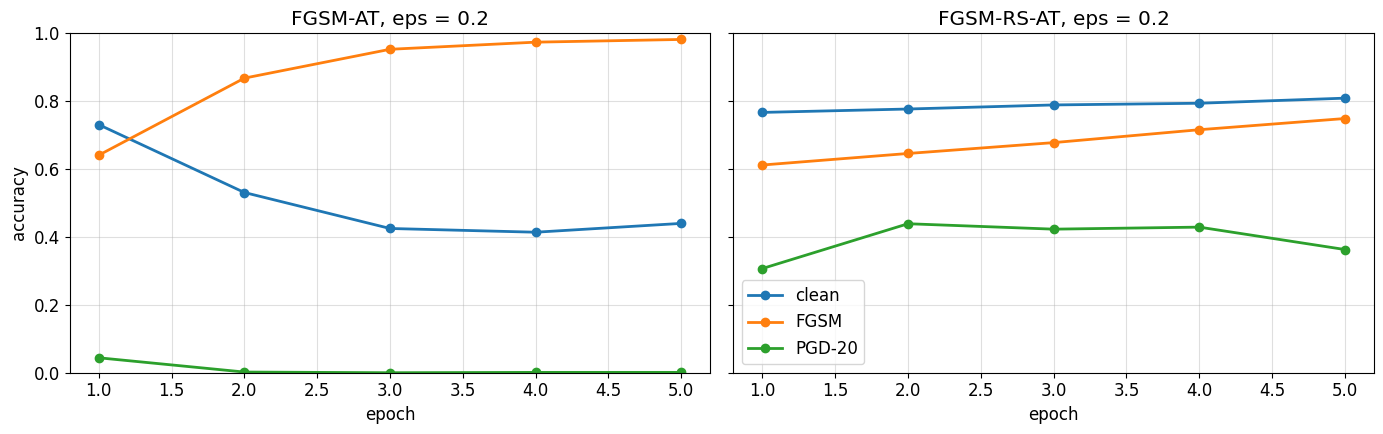

In [362]:
if '7.5' in BONUS_TASKS:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    for ax, (name, hist) in zip(axes, co_history.items()):
        epochs_axis = range(1, len(hist['clean']) + 1)
        for key, label in [('clean', 'clean'), ('fgsm', 'FGSM'), ('pgd', 'PGD-20')]:
            ax.plot(epochs_axis, hist[key], 'o-', linewidth=2, label=label)
        ax.set_title(f'{name}-AT, eps = {EPS_CO}')
        ax.set_xlabel('epoch')
        ax.grid(True, alpha=0.4)
    axes[0].set_ylabel('accuracy')
    axes[0].set_ylim(0, 1)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

In [363]:
if '7.5' in BONUS_TASKS:
    co_checks = {name: sanity_checks(robust[f'{name}, eps={EPS_CO}'], XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_CO)
                 for name in ['FGSM', 'FGSM-RS']}
    print(co_checks)

{'FGSM': {'fgsm': 0.44140625, 'pgd20': 0.0, 'pgd100_x5': 0.0, 'eps_1': 0.0}, 'FGSM-RS': {'fgsm': 0.73828125, 'pgd20': 0.3671875, 'pgd100_x5': 0.30859375, 'eps_1': 0.0}}


**Вопрос.** Был ли резкий спад PGD accuracy и на какой эпохе? Изменил ли картину random start? Сопоставьте динамику FGSM/PGD и результаты усиленной атаки. Если catastrophic overfitting не наблюдается, укажите это и предложите одну проверяемую гипотезу о том, от чего он мог бы зависеть.

**Ответ.** У FGSM-обучения catastrophic overfitting был, и очень быстро. Уже после 1-й эпохи PGD-20 accuracy всего 0.029, после 2-й 0.002, дальше ноль. При этом FGSM accuracy растёт: 0.58 → 0.82 → 0.94 → 0.97 → 0.97. А clean accuracy падает: 0.69 → 0.37. То есть на FGSM-примерах модель к концу права чаще, чем на чистых картинках: она научилась делать одношаговую атаку бесполезной, а не стала устойчивой. Явного «обрыва» посреди обучения при этом нет: при $\varepsilon = 0.2$ PGD accuracy так и не поднялась выше 0.03, коллапс начался на первой же эпохе.

Random start картину изменил сильно. У FGSM-RS PGD accuracy 0.31 после 1-й эпохи и 0.44 после 2-й, clean держится около 0.8 и растёт. Но и тут есть тревожный признак: на 5-й эпохе PGD упала с 0.43 до 0.37, а FGSM в это время выросла до 0.75. Разрыв FGSM–PGD расширился с 0.21 до 0.38 — похоже на начало того же эффекта, только медленнее. Что это коллапс, а не шум, по одной эпохе не скажешь.

Усиленная атака это подтверждает. FGSM-модель: fgsm 0.336 (с учётом clean-ошибок), а pgd20, pgd100×5 и eps=1 — все по нулю. Все sanity checks формально пройдены, а robustness нулевая — ровно ситуация из вопроса 6.2. У FGSM-RS: fgsm 0.742, pgd20 0.383, а pgd100×5 уже 0.305 — ещё 8 п.п. сверху. У PGD-AT в 6.2 усиление атаки не меняло ничего. Здесь меняет, значит, PGD-20 переоценивает устойчивость FGSM-RS модели, и часть её «робастности» — тоже маскировка градиента.

Проверяемая гипотеза: catastrophic overfitting у FGSM-RS зависит от размера шага $\alpha$ относительно $\varepsilon$. С $\alpha = 1.25\varepsilon$ шаг часто выходит далеко за шар и обрезается проекцией, и модель снова учится против почти детерминированного одношагового возмущения. Если повторить FGSM-RS с $\alpha = \varepsilon$ или меньше при том же $\varepsilon = 0.2$ и тех же 5 эпохах, падения PGD accuracy на последних эпохах быть не должно, а разрыв pgd20 / pgd100×5 должен сократиться.